# Equipo 4 – Práctica 3.5 Series de Tiempo
**Minería de Datos · Facultad de Ingeniería, UNAM**

**Equipo:** Luis Angel Echevarria Aguilar, Leonardo Alan Lee Roble, Luna Alberto Darwin Leonel

## 1. Objetivo del estudio

Pronosticar las ventas mensuales del medicamento **Tempra** en las farmacias de cada estado de la República incluidos en el archivo, comparando dos familias de modelos: **Triple Exponential Smoothing (Holt-Winters)** y **ARIMA/SARIMA**.

El pronóstico sirve para planear inventario y distribución: anticipar los meses de mayor demanda, evitar desabasto en los picos y sobreinventario en los valles. Para cada estado se busca:
- el modelo que pronostica con menor error;
- el horizonte (cuántos meses hacia adelante) en el que el pronóstico es confiable;
- los componentes de la serie (tendencia, ciclo, estacionalidad e irregular) y los valores atípicos;
- un pronóstico para los 12 meses siguientes (2021).

In [ ]:
import os, datetime, itertools
try:                                    # silencia el DeprecationWarning de utcnow() en Colab
    import jupyter_client.session as _jc
    _jc.utcnow = lambda: datetime.datetime.now(datetime.timezone.utc)
except Exception:
    pass

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.filters.hp_filter import hpfilter
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
import warnings, logging
warnings.filterwarnings('ignore')
logging.getLogger('statsmodels').setLevel(logging.ERROR)

AZUL, NARANJA, AQUA, GRIS, TINTA = '#2a78d6', '#eb6834', '#1baf7a', '#898781', '#0b0b0b'
COL = {'Holt-Winters': AZUL, 'SARIMA': NARANJA}
DIV = LinearSegmentedColormap.from_list('div', ['#2a78d6', '#f0efec', '#d9443b'])
plt.rcParams.update({
    'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb', 'savefig.facecolor': '#fcfcfb',
    'axes.edgecolor': '#c3c2b7', 'axes.labelcolor': '#52514e', 'text.color': TINTA,
    'xtick.color': '#52514e', 'ytick.color': '#52514e', 'axes.grid': True, 'grid.color': '#e1e0d9',
    'grid.linewidth': 0.8, 'axes.axisbelow': True, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.titlesize': 11.5, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left', 'figure.dpi': 100})
pd.set_option('display.float_format', lambda v: f'{v:,.2f}')
pd.set_option('display.width', 200)
MESES = ['Ene', 'Feb', 'Mar', 'Abr', 'May', 'Jun', 'Jul', 'Ago', 'Sep', 'Oct', 'Nov', 'Dic']

### 1.1 Carga del archivo
Se carga `TS_Medicamento_Tempra.xlsx`. En Colab, si el archivo no está en la carpeta de trabajo, la celda abre el selector para subirlo.

In [ ]:
ARCHIVO = 'TS Medicamento Tempra.xlsx'
if not os.path.exists(ARCHIVO):
    try:
        from google.colab import files
        print('Sube el archivo', ARCHIVO)
        ARCHIVO = list(files.upload().keys())[0]
    except ImportError:
        raise FileNotFoundError(f'No se encontró {ARCHIVO}')

df = pd.read_excel(ARCHIVO)
df.columns = df.columns.str.strip()
df['Fecha'] = pd.to_datetime(df['Fecha'])
print(f'Registros: {len(df)} | Medicamentos: {df["Medicamento"].unique().tolist()} | '
      f'Periodo: {df["Fecha"].min():%Y-%m} a {df["Fecha"].max():%Y-%m}')
display(df.head())

Registros: 420 | Medicamentos: ['TEMPRA'] | Periodo: 2016-01 a 2020-12


,Ciudad,Medicamento,Ventas,Fecha
0,CDMX,TEMPRA,22851,2016-01-01
1,CDMX,TEMPRA,20085,2016-02-01
2,CDMX,TEMPRA,35439,2016-03-01
3,CDMX,TEMPRA,25431,2016-04-01
4,CDMX,TEMPRA,26550,2016-05-01


## 2. Estructura y calidad de los datos

Se organiza una serie por estado (columnas) con una fila por mes. Se revisan faltantes, fechas duplicadas, la frecuencia real de las fechas y si hay series repetidas entre estados.

In [ ]:
ESTADO = {'CDMX': 'Ciudad de México', 'GUADALAJARA': 'Jalisco (Guadalajara)', 'GUANAJUATO': 'Guanajuato',
          'MORELIA': 'Michoacán (Morelia)', 'PUEBLA': 'Puebla', 'QUERETARO': 'Querétaro', 'VERACRUZ': 'Veracruz'}
serie = df.pivot_table(index='Fecha', columns='Ciudad', values='Ventas', aggfunc='sum').astype(float).sort_index()
serie.index.freq = 'MS'
ESTADOS = list(serie.columns)

resumen = pd.DataFrame({
    'Estado': [ESTADO.get(c, c) for c in ESTADOS],
    'Meses': serie.notna().sum().values,
    'Ventas promedio/mes': serie.mean().values,
    'Mínimo': serie.min().values, 'Máximo': serie.max().values,
    'Coef. de variación': (serie.std() / serie.mean()).values}, index=ESTADOS)
display(resumen)
print(f'Faltantes: {serie.isna().sum().sum()} | Fechas duplicadas por ciudad: {df.duplicated(["Ciudad", "Fecha"]).sum()}')
print(f'Días del mes presentes en las fechas: {sorted(df["Fecha"].dt.day.unique())} -> un registro por mes')

iguales = [(a, b) for a, b in itertools.combinations(ESTADOS, 2) if serie[a].equals(serie[b])]
for a, b in iguales:
    print(f'ATENCIÓN: {a} y {b} tienen exactamente las mismas ventas en los {len(serie)} meses '
          '(probable error de captura en el archivo). Se modelan ambos, pero sus resultados serán idénticos.')

,Estado,Meses,Ventas promedio/mes,Mínimo,Máximo,Coef. de variación
CDMX,Ciudad de México,60,"24,175.82","16,512.00","36,335.00",0.19
GUADALAJARA,Jalisco (Guadalajara),60,"8,366.82",0.00,"24,043.00",0.67
GUANAJUATO,Guanajuato,60,"6,590.50","2,840.00","10,053.00",0.27
MORELIA,Michoacán (Morelia),60,"6,076.27","2,128.00","9,632.00",0.27
PUEBLA,Puebla,60,150.07,53.00,347.00,0.42
QUERETARO,Querétaro,60,"31,705.03","21,835.00","51,337.00",0.19
VERACRUZ,Veracruz,60,"31,705.03","21,835.00","51,337.00",0.19


Faltantes: 0 | Fechas duplicadas por ciudad: 0
Días del mes presentes en las fechas: [np.int32(1)] -> un registro por mes
ATENCIÓN: QUERETARO y VERACRUZ tienen exactamente las mismas ventas en los 60 meses (probable error de captura en el archivo). Se modelan ambos, pero sus resultados serán idénticos.


## 3. Exploración de las series

Cada panel muestra la serie mensual de un estado con su propia escala (los volúmenes son muy distintos: Puebla vende alrededor de 150 unidades al mes y Querétaro más de 30,000). Se buscan tendencia, picos repetidos y valores fuera de lo normal.

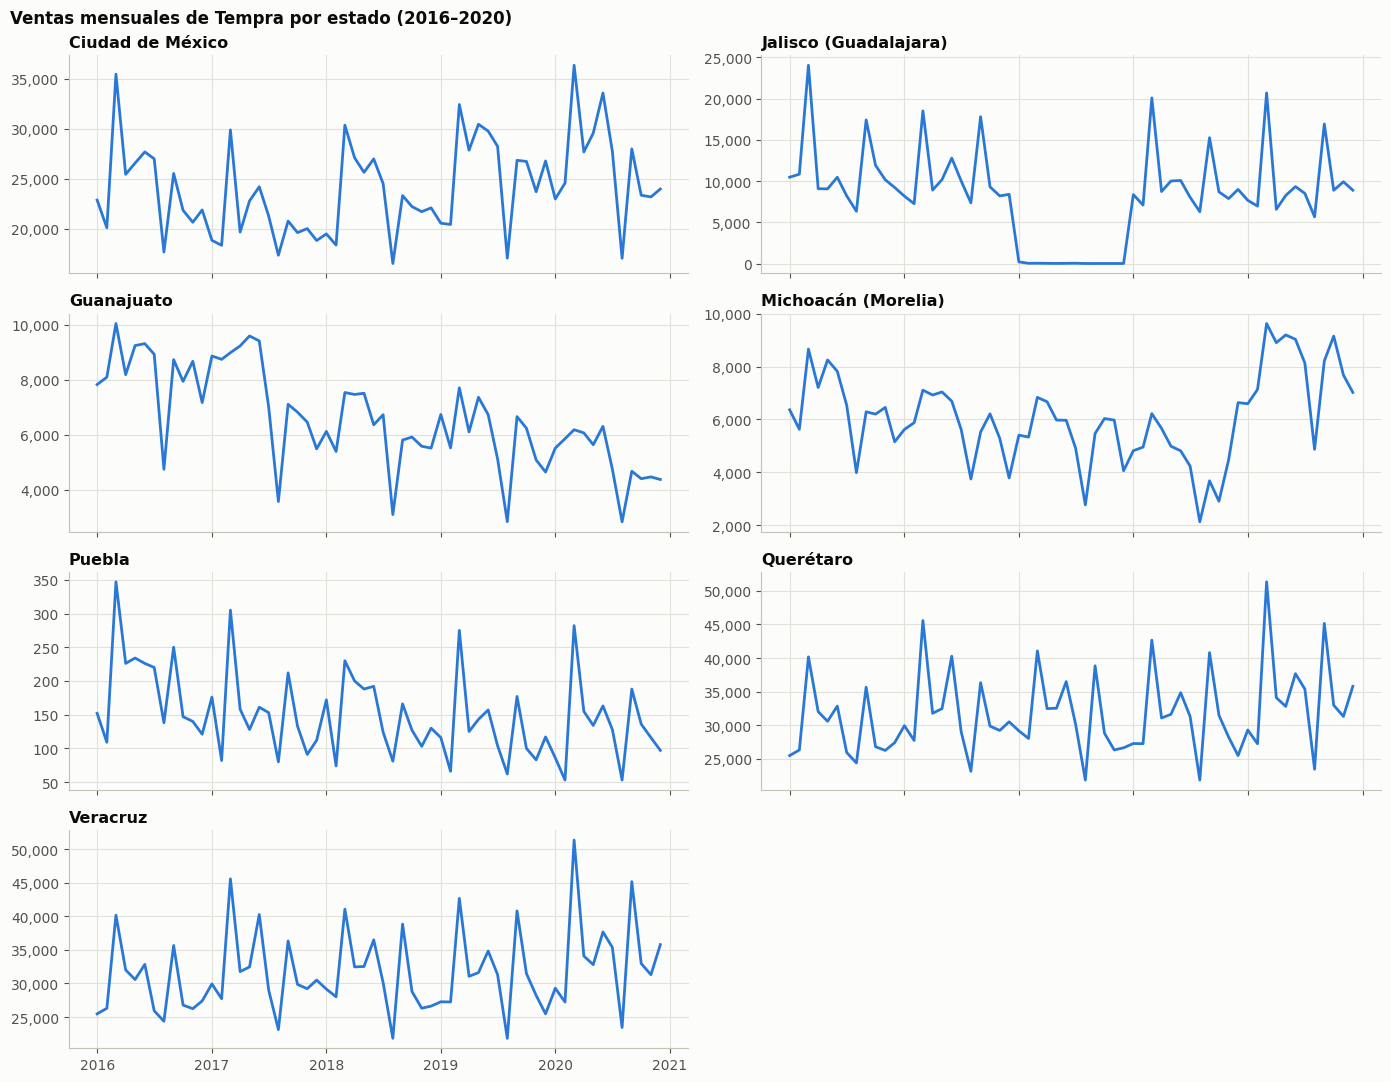

In [ ]:
fig, axes = plt.subplots(4, 2, figsize=(14, 11), sharex=True)
for a, c in zip(axes.ravel(), ESTADOS):
    a.plot(serie.index, serie[c], color=AZUL, lw=2)
    a.set_title(ESTADO[c]); a.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:,.0f}'))
axes.ravel()[-1].axis('off')
plt.suptitle('Ventas mensuales de Tempra por estado (2016–2020)', x=.01, ha='left', fontweight='bold')
plt.tight_layout(); plt.show()

### 3.1 Patrón estacional
Índice de cada mes = ventas del mes ÷ promedio mensual de ese año (1 = mes promedio); se reporta la mediana de los 5 años para que un año con registros anómalos no distorsione el patrón. Rojo indica meses por encima del promedio y azul por debajo. Si el patrón se repite en todos los estados, la estacionalidad es del producto y no de una región.

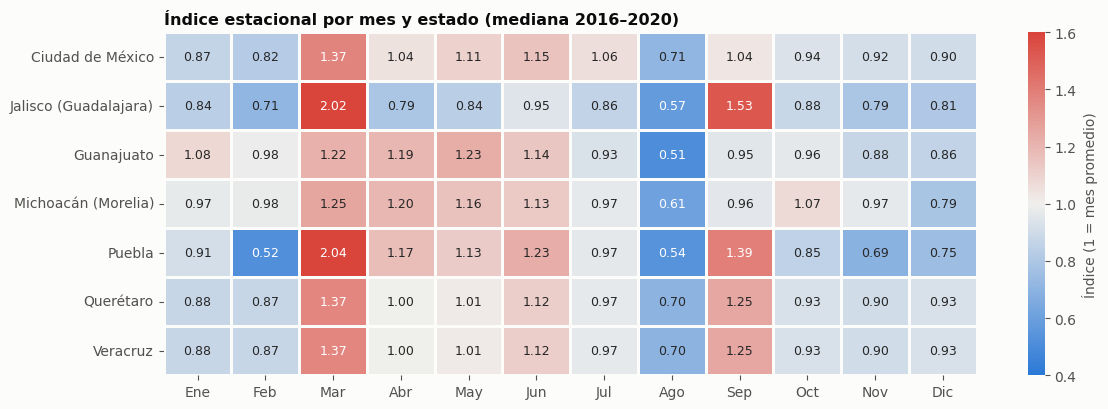

Mes más alto por estado: {'Ciudad de México': 'Mar', 'Jalisco (Guadalajara)': 'Mar', 'Guanajuato': 'May', 'Michoacán (Morelia)': 'Mar', 'Puebla': 'Mar', 'Querétaro': 'Mar', 'Veracruz': 'Mar'}
Mes más bajo por estado: {'Ciudad de México': 'Ago', 'Jalisco (Guadalajara)': 'Ago', 'Guanajuato': 'Ago', 'Michoacán (Morelia)': 'Ago', 'Puebla': 'Feb', 'Querétaro': 'Ago', 'Veracruz': 'Ago'}


In [ ]:
indice = serie.groupby(serie.index.year).transform(lambda s: s / s.mean())
perfil = indice.groupby(indice.index.month).median().T
perfil.columns = ['Ene', 'Feb', 'Mar', 'Abr', 'May', 'Jun', 'Jul', 'Ago', 'Sep', 'Oct', 'Nov', 'Dic']
perfil.index = [ESTADO[c] for c in perfil.index]
fig, ax = plt.subplots(figsize=(12, 4.2))
sns.heatmap(perfil, cmap=DIV, center=1, vmin=.4, vmax=1.6, annot=True, fmt='.2f', annot_kws={'size': 9},
            linewidths=2, linecolor='#fcfcfb', cbar_kws={'label': 'Índice (1 = mes promedio)'}, ax=ax)
ax.set_title('Índice estacional por mes y estado (mediana 2016–2020)'); ax.grid(False)
plt.tight_layout(); plt.show()
print('Mes más alto por estado:', perfil.idxmax(axis=1).to_dict())
print('Mes más bajo por estado:', perfil.idxmin(axis=1).to_dict())

## 4. Selección del intervalo de tiempo (Día, Semana, Quincena o Mes)

El archivo trae **un registro por mes** (todas las fechas son día 1), así que no es posible pronosticar por día, semana o quincena: habría que inventar cómo se reparten las ventas dentro del mes. Las alternativas reales son el mes o agrupaciones mayores (bimestre, trimestre).

Para comparar, se agrega la serie a cada intervalo, se entrena Holt-Winters con todo menos el último año y se mide el error porcentual (MAPE) en 2020. También se cuenta cuántas observaciones y ciclos estacionales completos quedan para entrenar.

In [ ]:
def mape(real, pron):
    real, pron = np.asarray(real, float), np.asarray(pron, float)
    return np.mean(np.abs((real - pron) / real)) * 100

def hw_rapido(y, m):
    return ExponentialSmoothing(y, trend='add', seasonal='mul', seasonal_periods=m,
                                initialization_method='estimated').fit()

# Para esta comparación se usa la serie original; Jalisco se omite porque su 2018 está vacío (sección 5)
comparables = [c for c in ESTADOS if c != 'GUADALAJARA']
filas = []
for nombre, regla, m in [('Mes', 'MS', 12), ('Bimestre', '2MS', 6), ('Trimestre', 'QS', 4)]:
    agg = serie[comparables].resample(regla).sum()
    errores = [mape(agg[c].iloc[-m:], hw_rapido(agg[c].iloc[:-m], m).forecast(m)) for c in comparables]
    filas.append({'Intervalo': nombre, 'Observaciones': len(agg), 'Obs. para entrenar': len(agg) - m,
                  'Ciclos estacionales para entrenar': (len(agg) - m) // m, 'Periodos por año': m,
                  'MAPE promedio 2020 (%)': np.mean(errores)})
tab_int = pd.DataFrame(filas).set_index('Intervalo')
display(tab_int)

,Observaciones,Obs. para entrenar,Ciclos estacionales para entrenar,Periodos por año,MAPE promedio 2020 (%)
Intervalo,,,,,
Mes,60,48,4,12,17.99
Bimestre,30,24,4,6,16.85
Trimestre,20,16,4,4,16.03


**Decisión: intervalo mensual.** Agregar a bimestre o trimestre suaviza la serie y suele bajar el error porcentual, pero deja muy pocas observaciones para entrenar (24 bimestres o 16 trimestres) y, sobre todo, **borra los picos de marzo y septiembre y el valle de agosto**, que son justo lo que el negocio necesita anticipar para abastecer las farmacias. El mes es el intervalo más fino disponible, conserva 4 ciclos completos para entrenar y es la unidad natural para planear compras.

## 5. Detección de valores atípicos (outliers)

Se aplican dos reglas sobre la serie mensual de cada estado:
1. **Registro anómalo:** ventas menores al 10% de la mediana del mismo mes en los demás años. Indica un error de captura o un periodo sin registro, no una caída real de demanda.
2. **Atípico estadístico:** se descompone la serie con STL robusto (tendencia + estacionalidad + residuo) y se marca el mes cuyo residuo está a más de 3 desviaciones estándar de la media de los residuos. El STL robusto evita que los propios atípicos deformen la tendencia y la estacionalidad.

Los registros anómalos se reemplazan por el promedio del mismo mes en los otros años, para no entrenar los modelos con ceros falsos. Los atípicos estadísticos se conservan y se señalan, porque pueden ser ventas reales (promociones, brotes de enfermedades).

Registros anómalos: 12 | Atípicos estadísticos: 11


,Estado,Fecha,Ventas,Tipo,Valor usado
0,Ciudad de México,2018-04,"27,083.00",Atípico estadístico (z = +3.8),"27,083.00"
1,Jalisco (Guadalajara),2018-01,198.00,Registro anómalo (imputado),"8,663.75"
2,Jalisco (Guadalajara),2018-02,26.00,Registro anómalo (imputado),"8,032.25"
3,Jalisco (Guadalajara),2018-03,34.00,Registro anómalo (imputado),"20,829.75"
4,Jalisco (Guadalajara),2018-04,21.00,Registro anómalo (imputado),"8,316.25"
5,Jalisco (Guadalajara),2018-05,10.00,Registro anómalo (imputado),"9,372.75"
6,Jalisco (Guadalajara),2018-06,22.00,Registro anómalo (imputado),"10,660.00"
7,Jalisco (Guadalajara),2018-07,35.00,Registro anómalo (imputado),"8,687.00"
8,Jalisco (Guadalajara),2018-08,0.00,Registro anómalo (imputado),"6,409.00"
9,Jalisco (Guadalajara),2018-09,3.00,Registro anómalo (imputado),"16,849.00"


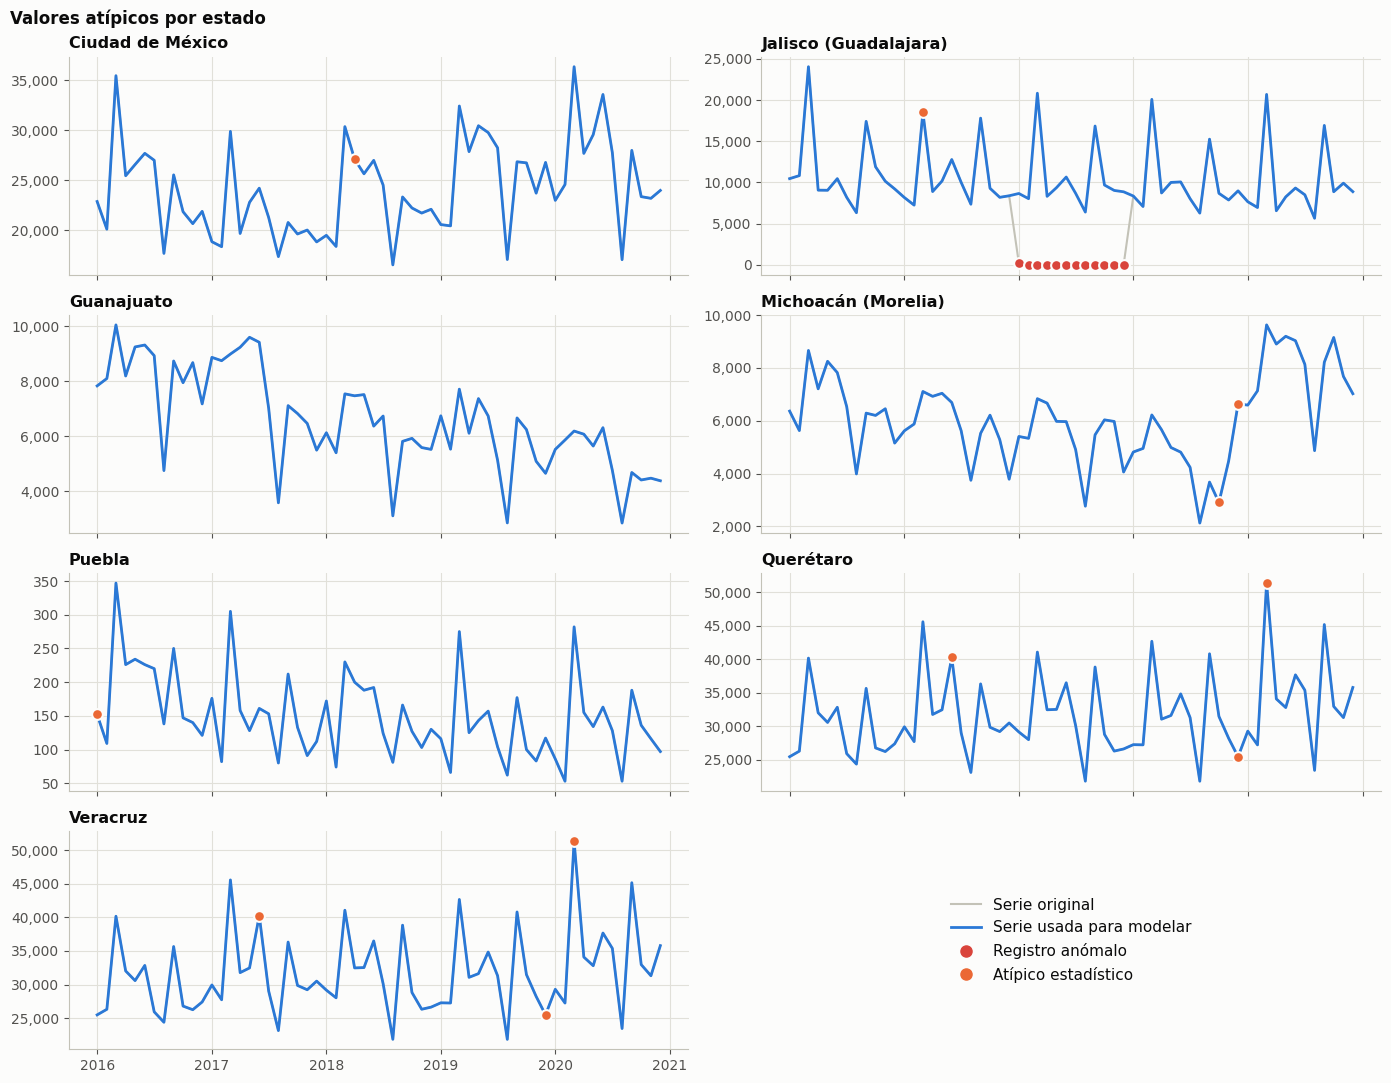

In [ ]:
limpia = serie.copy()
registros = []
for c in ESTADOS:
    s = serie[c]
    mediana_mes = s.groupby(s.index.month).transform('median')
    anomalo = s < 0.10 * mediana_mes
    s_l = s.mask(anomalo)
    limpia[c] = s_l.fillna(s_l.groupby(s_l.index.month).transform('mean'))
    stl = STL(limpia[c], period=12, seasonal=13, robust=True).fit()
    r = stl.resid
    z = (r - r.mean()) / r.std()
    for f in s.index[anomalo]:
        registros.append({'Estado': ESTADO[c], 'Fecha': f.strftime('%Y-%m'), 'Ventas': s[f], 'Tipo': 'Registro anómalo (imputado)',
                          'Valor usado': limpia.loc[f, c]})
    for f in s.index[(z.abs() > 3) & ~anomalo]:
        registros.append({'Estado': ESTADO[c], 'Fecha': f.strftime('%Y-%m'), 'Ventas': s[f],
                          'Tipo': f'Atípico estadístico (z = {z[f]:+.1f})', 'Valor usado': s[f]})

tab_out = pd.DataFrame(registros)
print(f'Registros anómalos: {(tab_out["Tipo"].str.startswith("Registro")).sum()} | '
      f'Atípicos estadísticos: {(tab_out["Tipo"].str.startswith("Atípico")).sum()}')
display(tab_out)

fig, axes = plt.subplots(4, 2, figsize=(14, 11), sharex=True)
for a, c in zip(axes.ravel(), ESTADOS):
    a.plot(serie.index, serie[c], color='#c3c2b7', lw=1.5, label='Original')
    a.plot(limpia.index, limpia[c], color=AZUL, lw=2, label='Usada para modelar')
    sub = tab_out[tab_out['Estado'] == ESTADO[c]]
    for _, rw in sub.iterrows():
        f = pd.Timestamp(rw['Fecha'])
        a.scatter(f, rw['Ventas'], s=60, zorder=3, edgecolor='#fcfcfb', linewidth=1.5,
                  color=NARANJA if rw['Tipo'].startswith('Atípico') else '#d9443b')
    a.set_title(ESTADO[c]); a.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:,.0f}'))
axes.ravel()[-1].axis('off')
h = [plt.Line2D([], [], color='#c3c2b7', lw=1.5), plt.Line2D([], [], color=AZUL, lw=2),
     plt.Line2D([], [], marker='o', ls='', color='#d9443b', markersize=8), plt.Line2D([], [], marker='o', ls='', color=NARANJA, markersize=8)]
axes.ravel()[-1].legend(h, ['Serie original', 'Serie usada para modelar', 'Registro anómalo', 'Atípico estadístico'],
                        loc='center', frameon=False, fontsize=11)
plt.suptitle('Valores atípicos por estado', x=.01, ha='left', fontweight='bold')
plt.tight_layout(); plt.show()

## 6. Partición entrenamiento / prueba

En series de tiempo no se parte al azar: se respeta el orden. Se entrena con **2016–2019 (48 meses)** y se prueba con **2020 (12 meses)**, simulando que a fines de 2019 se pronostica el año siguiente. Las métricas son:
- **MAPE:** error porcentual promedio (permite comparar estados con volúmenes distintos).
- **MAE:** error promedio en unidades.
- **RMSE:** raíz del error cuadrático medio; castiga más los errores grandes.

In [ ]:
H = 12
train, test = limpia.iloc[:-H], limpia.iloc[-H:]
print(f'Entrenamiento: {train.index.min():%Y-%m} a {train.index.max():%Y-%m} ({len(train)} meses)')
print(f'Prueba:        {test.index.min():%Y-%m} a {test.index.max():%Y-%m} ({len(test)} meses)')

def metricas(real, pron):
    e = np.asarray(real) - np.asarray(pron)
    return {'MAPE (%)': mape(real, pron), 'MAE': np.mean(np.abs(e)), 'RMSE': np.sqrt(np.mean(e ** 2))}

Entrenamiento: 2016-01 a 2019-12 (48 meses)
Prueba:        2020-01 a 2020-12 (12 meses)


## 7. Triple Exponential Smoothing (Holt-Winters)

Holt-Winters suaviza tres componentes a la vez: **nivel**, **tendencia** y **estacionalidad** (periodo de 12 meses). Para cada estado se prueban cuatro variantes y se elige la de menor AICc:
- estacionalidad **aditiva** (el pico suma las mismas unidades cada año) o **multiplicativa** (el pico es un porcentaje del nivel);
- tendencia **lineal** o **amortiguada** (*damped*, que se aplana con el tiempo).

In [ ]:
def ajustar_hw(y):
    mejor = None
    for est, amort in itertools.product(['add', 'mul'], [False, True]):
        m = ExponentialSmoothing(y, trend='add', seasonal=est, seasonal_periods=12, damped_trend=amort,
                                 initialization_method='estimated').fit()
        if mejor is None or m.aicc < mejor.aicc:
            mejor, conf = m, {'Estacionalidad': 'multiplicativa' if est == 'mul' else 'aditiva',
                              'Tendencia': 'amortiguada' if amort else 'lineal'}
    return mejor, conf

hw, pron_hw, filas = {}, {}, []
for c in ESTADOS:
    m, conf = ajustar_hw(train[c])
    hw[c], pron_hw[c] = m, m.forecast(H)
    filas.append({'Estado': ESTADO[c], **conf, 'alfa (nivel)': m.params['smoothing_level'],
                  'beta (tendencia)': m.params['smoothing_trend'], 'gamma (estacional)': m.params['smoothing_seasonal'],
                  **metricas(test[c], pron_hw[c])})
tab_hw = pd.DataFrame(filas).set_index('Estado')
display(tab_hw)

,Estacionalidad,Tendencia,alfa (nivel),beta (tendencia),gamma (estacional),MAPE (%),MAE,RMSE
Estado,,,,,,,,
Ciudad de México,multiplicativa,lineal,0.32,0.17,0.00,13.56,"3,321.52","3,710.18"
Jalisco (Guadalajara),multiplicativa,amortiguada,0.80,0.00,0.00,10.50,848.31,"1,008.28"
Guanajuato,multiplicativa,lineal,0.32,0.00,0.00,7.23,360.72,404.49
Michoacán (Morelia),multiplicativa,lineal,0.00,0.00,0.00,48.83,"3,894.56","3,973.47"
Puebla,multiplicativa,lineal,0.20,0.00,0.00,21.94,29.38,34.62
Querétaro,multiplicativa,lineal,0.22,0.00,0.00,8.20,"3,138.53","4,246.04"
Veracruz,multiplicativa,lineal,0.22,0.00,0.00,8.20,"3,138.53","4,246.04"


### 7.1 Descomposición: tendencia, ciclicidad, estacionalidad e irregular
Holt-Winters separa el **nivel** (tendencia-ciclo), la **estacionalidad** y el error. Para distinguir la tendencia de largo plazo de las oscilaciones de varios meses (ciclo), al nivel se le aplica el filtro de Hodrick-Prescott (λ = 14,400, valor usual para datos mensuales):
- **Tendencia:** dirección de largo plazo de las ventas.
- **Ciclicidad:** subidas y bajadas de varios meses alrededor de la tendencia (nivel − tendencia).
- **Estacionalidad:** patrón que se repite cada año; en el modelo multiplicativo es un factor (1.3 = 30% arriba del nivel).
- **Irregular:** lo que el modelo no explica (real − ajustado).

La descomposición se hace con el modelo ajustado sobre la serie completa 2016–2020.

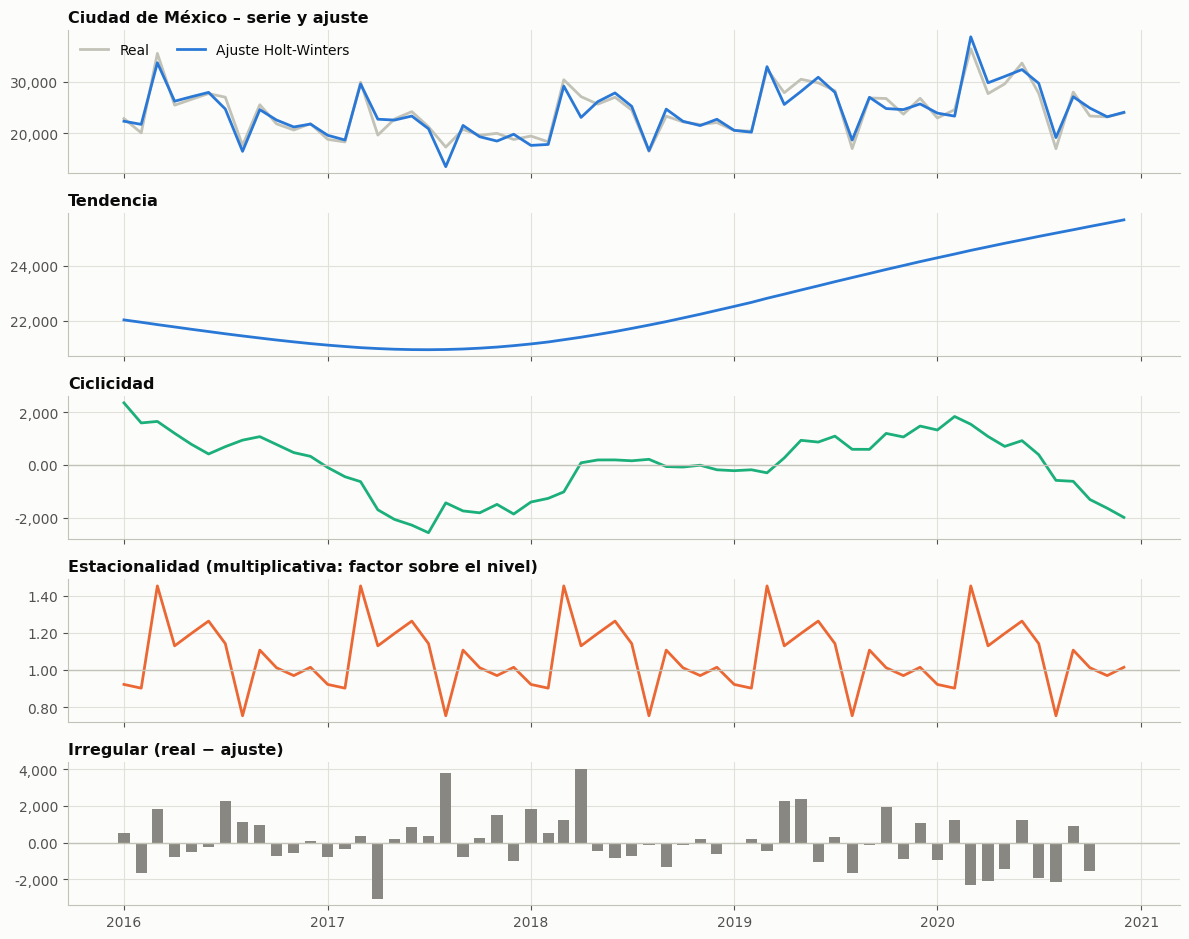

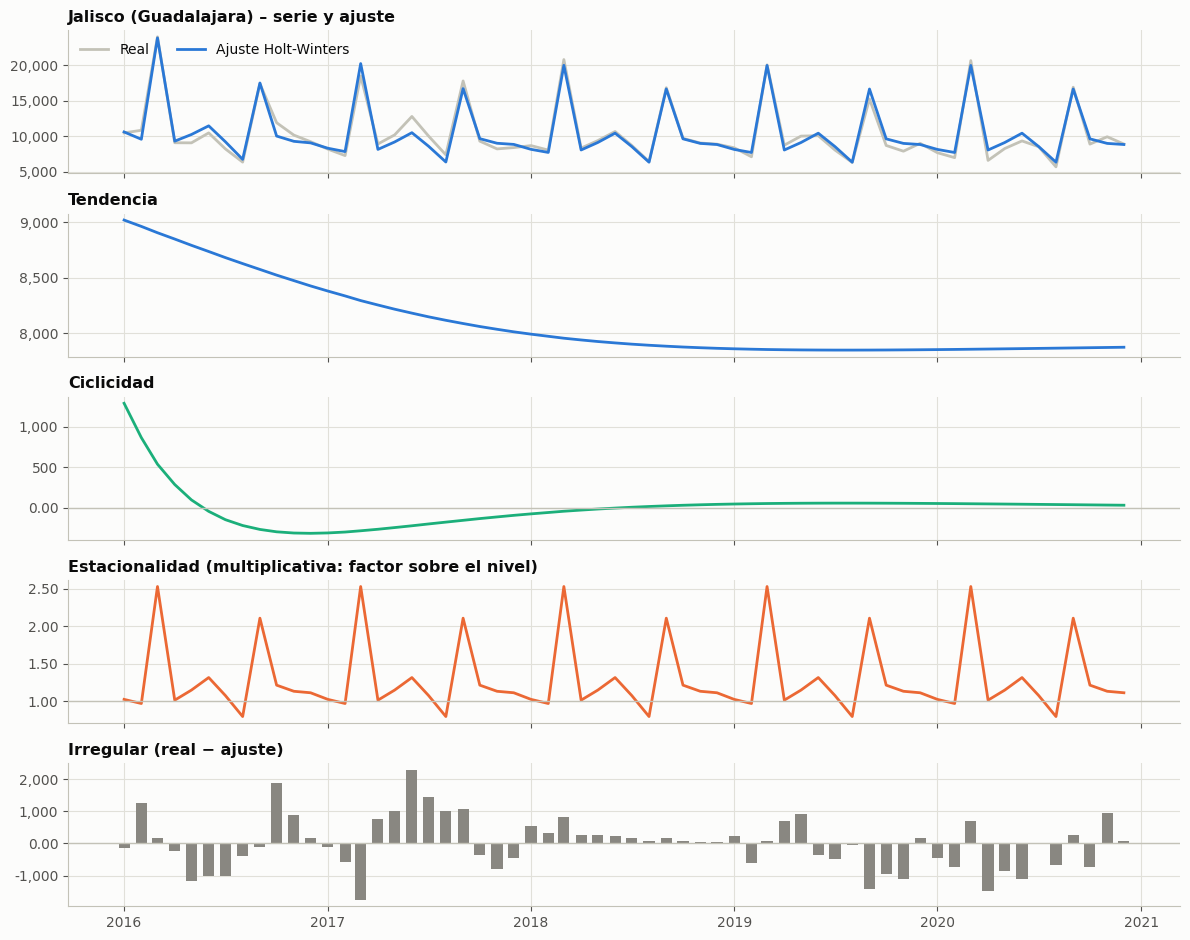

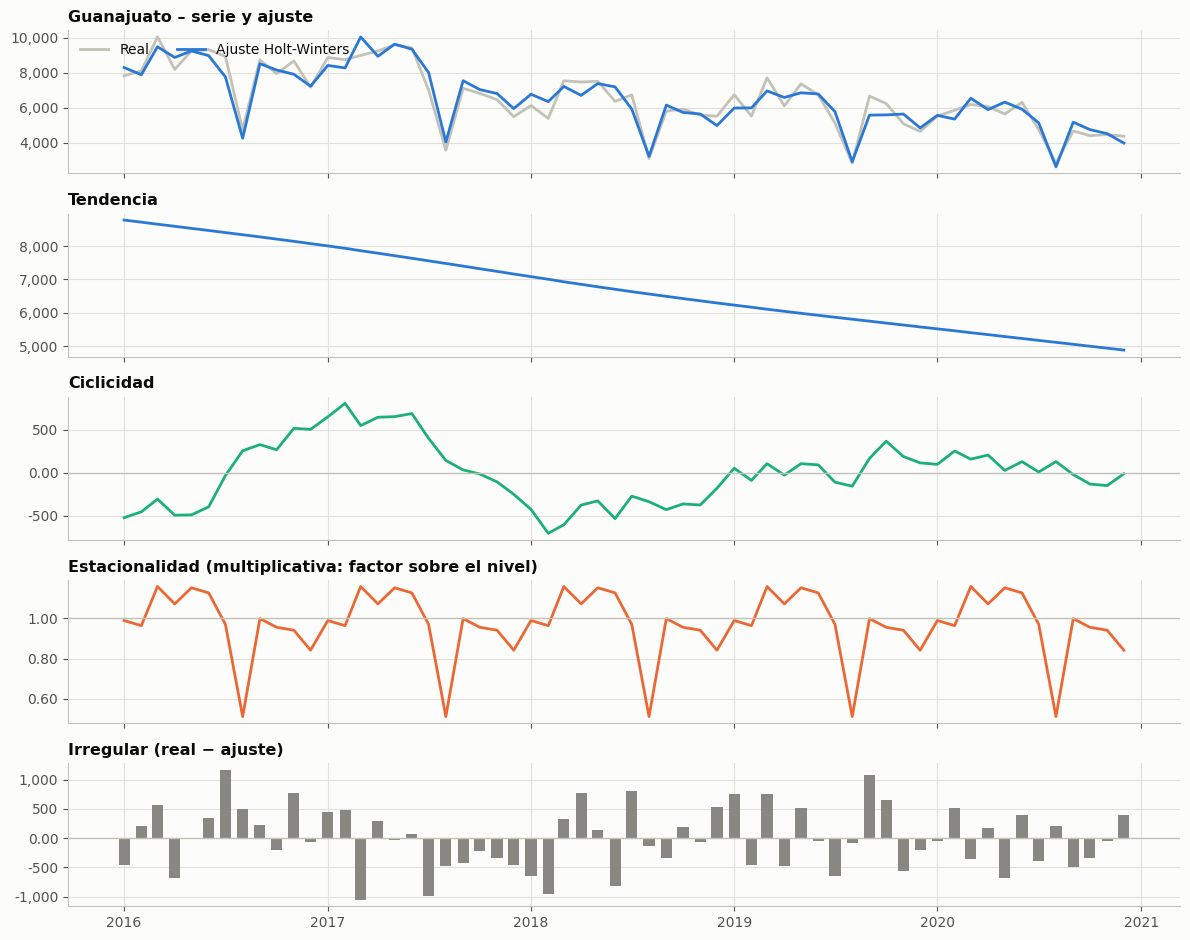

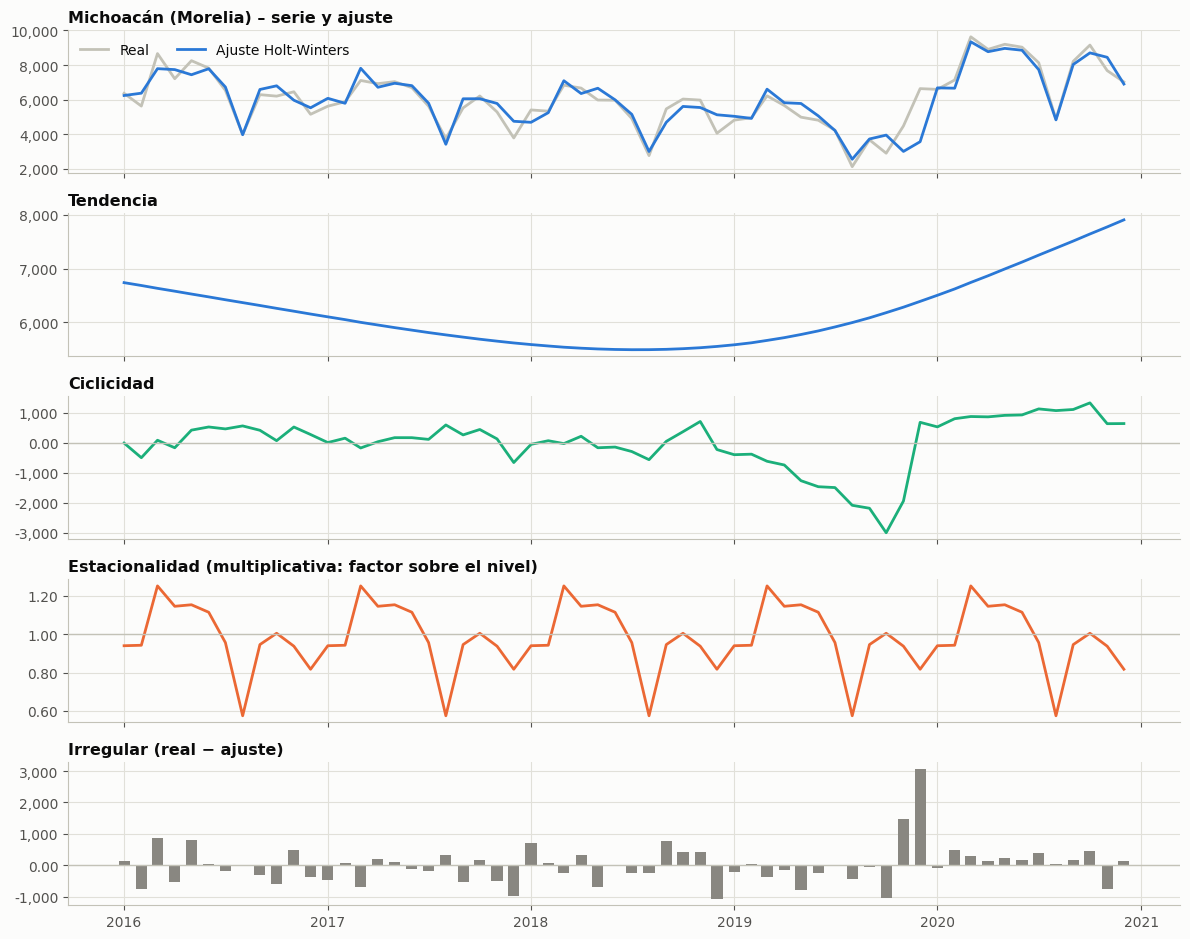

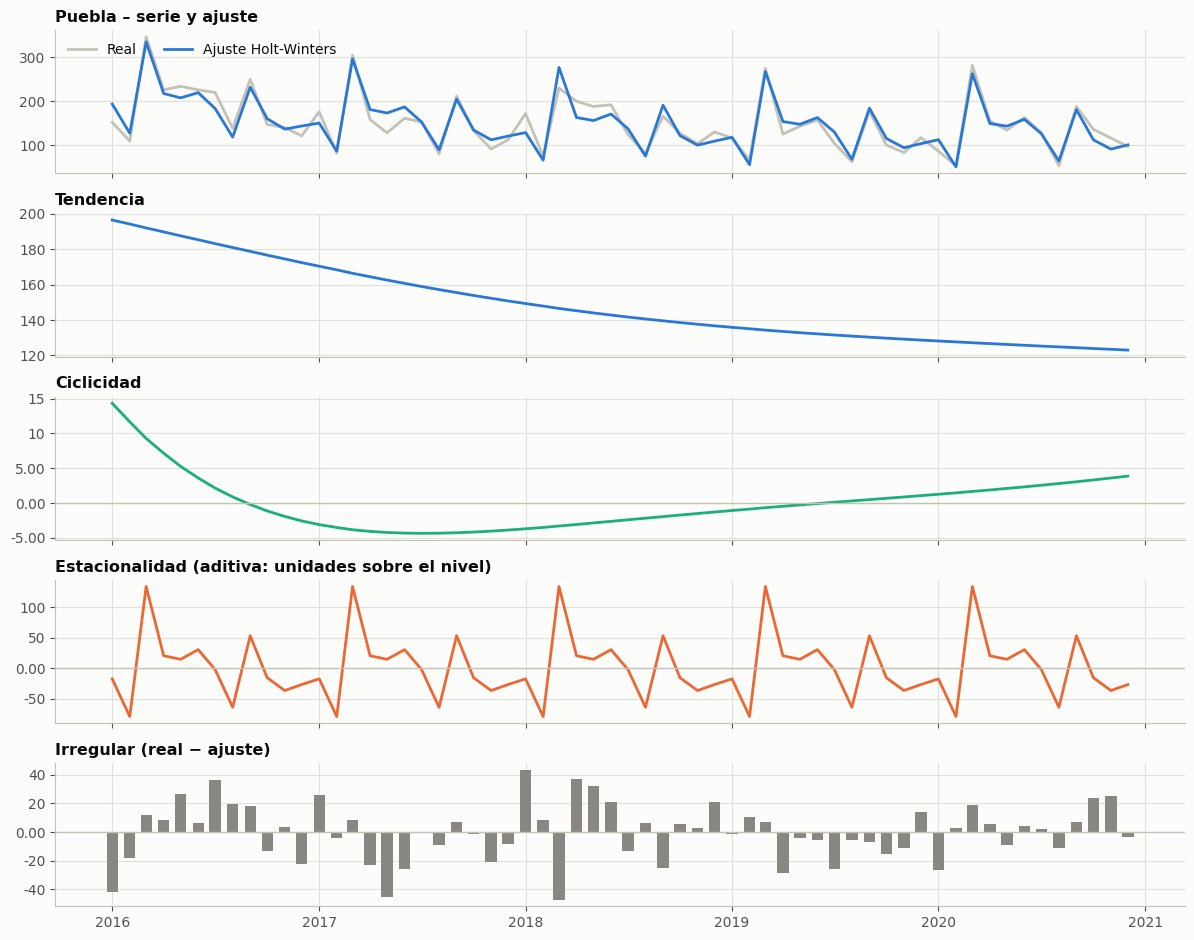

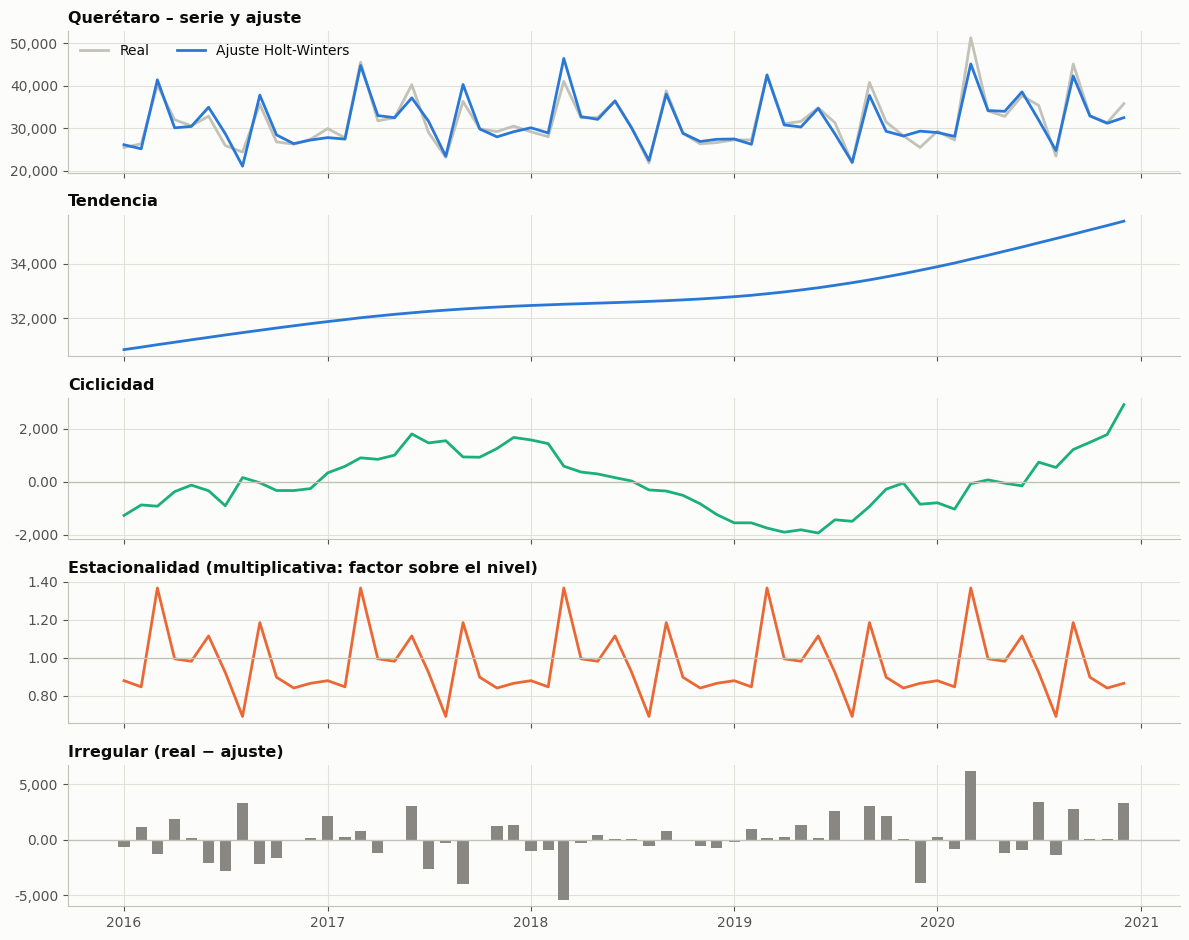

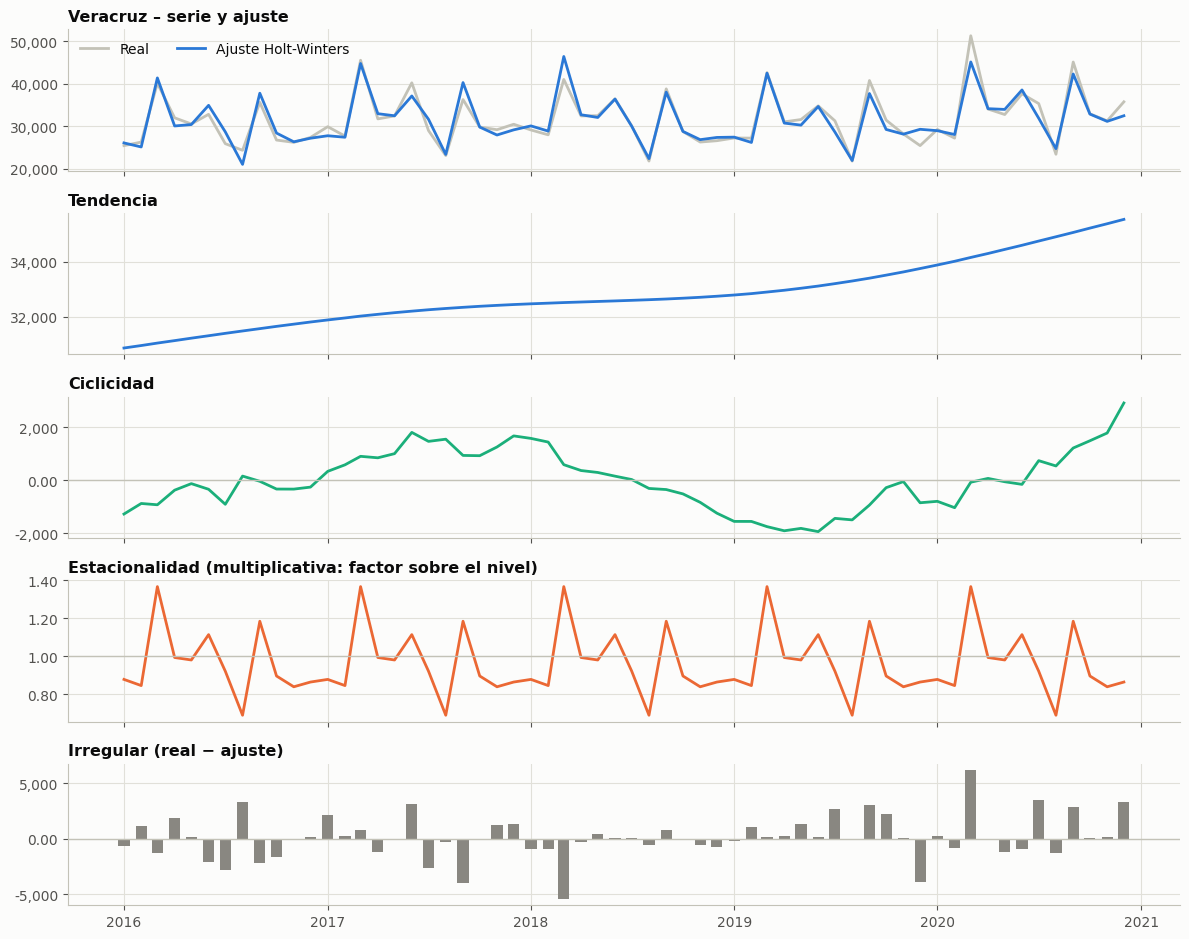

,Cambio de tendencia 2016→2020 (%),Amplitud del ciclo (% del nivel),Mes con mayor estacionalidad,Mes con menor estacionalidad,"Irregular (% de la serie, desv.)"
Estado,,,,,
Ciudad de México,16.51,11.42,Mar,Ago,5.84
Jalisco (Guadalajara),-12.72,15.89,Mar,Ago,7.87
Guanajuato,-44.33,11.99,Mar,Ago,8.06
Michoacán (Morelia),17.33,48.51,Mar,Ago,10.51
Puebla,-37.40,9.62,Mar,Feb,13.36
Querétaro,15.27,8.90,Mar,Ago,6.16
Veracruz,15.27,8.90,Mar,Ago,6.16


In [ ]:
hw_full, comp = {}, {}
for c in ESTADOS:
    m, conf = ajustar_hw(limpia[c])
    hw_full[c] = m
    nivel = pd.Series(m.level, index=limpia.index)
    ciclo, tend = hpfilter(nivel, lamb=14400)
    est = pd.Series(m.season, index=limpia.index)
    comp[c] = pd.DataFrame({'Serie': limpia[c], 'Ajuste': m.fittedvalues, 'Tendencia': tend, 'Ciclicidad': ciclo,
                            'Estacionalidad': est, 'Irregular': limpia[c] - m.fittedvalues})
    tipo = conf['Estacionalidad']
    fig, axes = plt.subplots(5, 1, figsize=(12, 9.5), sharex=True)
    axes[0].plot(limpia.index, limpia[c], color='#c3c2b7', lw=2, label='Real')
    axes[0].plot(limpia.index, m.fittedvalues, color=AZUL, lw=2, label='Ajuste Holt-Winters')
    axes[0].legend(frameon=False, ncol=2, loc='upper left'); axes[0].set_title(f'{ESTADO[c]} – serie y ajuste')
    axes[1].plot(tend.index, tend, color=AZUL, lw=2); axes[1].set_title('Tendencia')
    axes[2].plot(ciclo.index, ciclo, color=AQUA, lw=2); axes[2].axhline(0, color='#c3c2b7', lw=1); axes[2].set_title('Ciclicidad')
    axes[3].plot(est.index, est, color=NARANJA, lw=2)
    axes[3].axhline(1 if tipo == 'multiplicativa' else 0, color='#c3c2b7', lw=1)
    axes[3].set_title(f'Estacionalidad ({tipo}: ' + ('factor sobre el nivel)' if tipo == 'multiplicativa' else 'unidades sobre el nivel)'))
    axes[4].bar(limpia.index, comp[c]['Irregular'], width=20, color=GRIS); axes[4].axhline(0, color='#c3c2b7', lw=1)
    axes[4].set_title('Irregular (real − ajuste)')
    for a in axes: a.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:,.2f}' if abs(v) < 10 else f'{v:,.0f}'))
    plt.tight_layout(); plt.show()

# Resumen numérico de la descomposición
filas = []
for c in ESTADOS:
    k = comp[c]
    t0, t1 = k['Tendencia'].iloc[0], k['Tendencia'].iloc[-1]
    e = k['Estacionalidad'].iloc[-12:]
    filas.append({'Estado': ESTADO[c], 'Cambio de tendencia 2016→2020 (%)': (t1 / t0 - 1) * 100,
                  'Amplitud del ciclo (% del nivel)': (k['Ciclicidad'].abs().max() / k['Tendencia'].mean()) * 100,
                  'Mes con mayor estacionalidad': MESES[e.idxmax().month - 1], 'Mes con menor estacionalidad': MESES[e.idxmin().month - 1],
                  'Irregular (% de la serie, desv.)': k['Irregular'].std() / k['Serie'].mean() * 100})
tab_desc = pd.DataFrame(filas).set_index('Estado')
display(tab_desc)

## 8. ARIMA / SARIMA

SARIMA(p,d,q)(P,D,Q)₁₂ modela la serie con sus propios valores pasados (parte AR), con los errores pasados (parte MA) y con los mismos términos a 12 meses (parte estacional). Requiere una serie **estacionaria** (media y varianza constantes), que se logra diferenciando.

### 8.1 Estacionariedad (prueba de Dickey-Fuller aumentada)
Si el p-valor es menor que 0.05 la serie es estacionaria. Por la fuerte estacionalidad se aplica siempre una diferencia estacional (D = 1); si después de ella la serie sigue sin ser estacionaria se agrega una diferencia regular (d = 1).

In [ ]:
filas, ordenes_d = [], {}
for c in ESTADOS:
    y = train[c]
    p0 = adfuller(y)[1]; p12 = adfuller(y.diff(12).dropna())[1]
    d = 0 if p12 < .05 else 1
    p_fin = adfuller(y.diff(12).diff().dropna())[1] if d else p12
    ordenes_d[c] = d
    filas.append({'Estado': ESTADO[c], 'p ADF original': p0, 'p ADF tras dif. estacional': p12,
                  'd elegido': d, 'D elegido': 1, 'p ADF serie final': p_fin,
                  '¿Estacionaria?': 'sí' if p_fin < .05 else 'marginal'})
tab_adf = pd.DataFrame(filas).set_index('Estado')
display(tab_adf.style.format({'p ADF original': '{:.3f}', 'p ADF tras dif. estacional': '{:.3f}', 'p ADF serie final': '{:.3f}'}))

,p ADF original,p ADF tras dif. estacional,d elegido,D elegido,p ADF serie final,¿Estacionaria?
Estado,,,,,,
Ciudad de México,0.091,0.369,1,1,0.003,sí
Jalisco (Guadalajara),0.071,0.000,0,1,0.000,sí
Guanajuato,0.003,0.009,0,1,0.009,sí
Michoacán (Morelia),0.004,0.258,1,1,0.234,marginal
Puebla,0.490,0.000,0,1,0.000,sí
Querétaro,0.001,0.000,0,1,0.000,sí
Veracruz,0.001,0.000,0,1,0.000,sí


### 8.2 ACF y PACF
La **ACF** (autocorrelación) mide cuánto se parece la serie diferenciada a sí misma k meses antes; la **PACF** (autocorrelación parcial) mide lo mismo quitando el efecto de los rezagos intermedios. Las barras fuera de la banda azul son significativas:
- Un corte abrupto en la PACF sugiere el orden **p** (AR); un corte en la ACF sugiere el orden **q** (MA).
- Una barra significativa en el rezago 12 indica términos estacionales (P o Q).

Como guía final se ajustan todas las combinaciones p, q ∈ {0, 1, 2} y P, Q ∈ {0, 1} y se elige la de menor AIC.

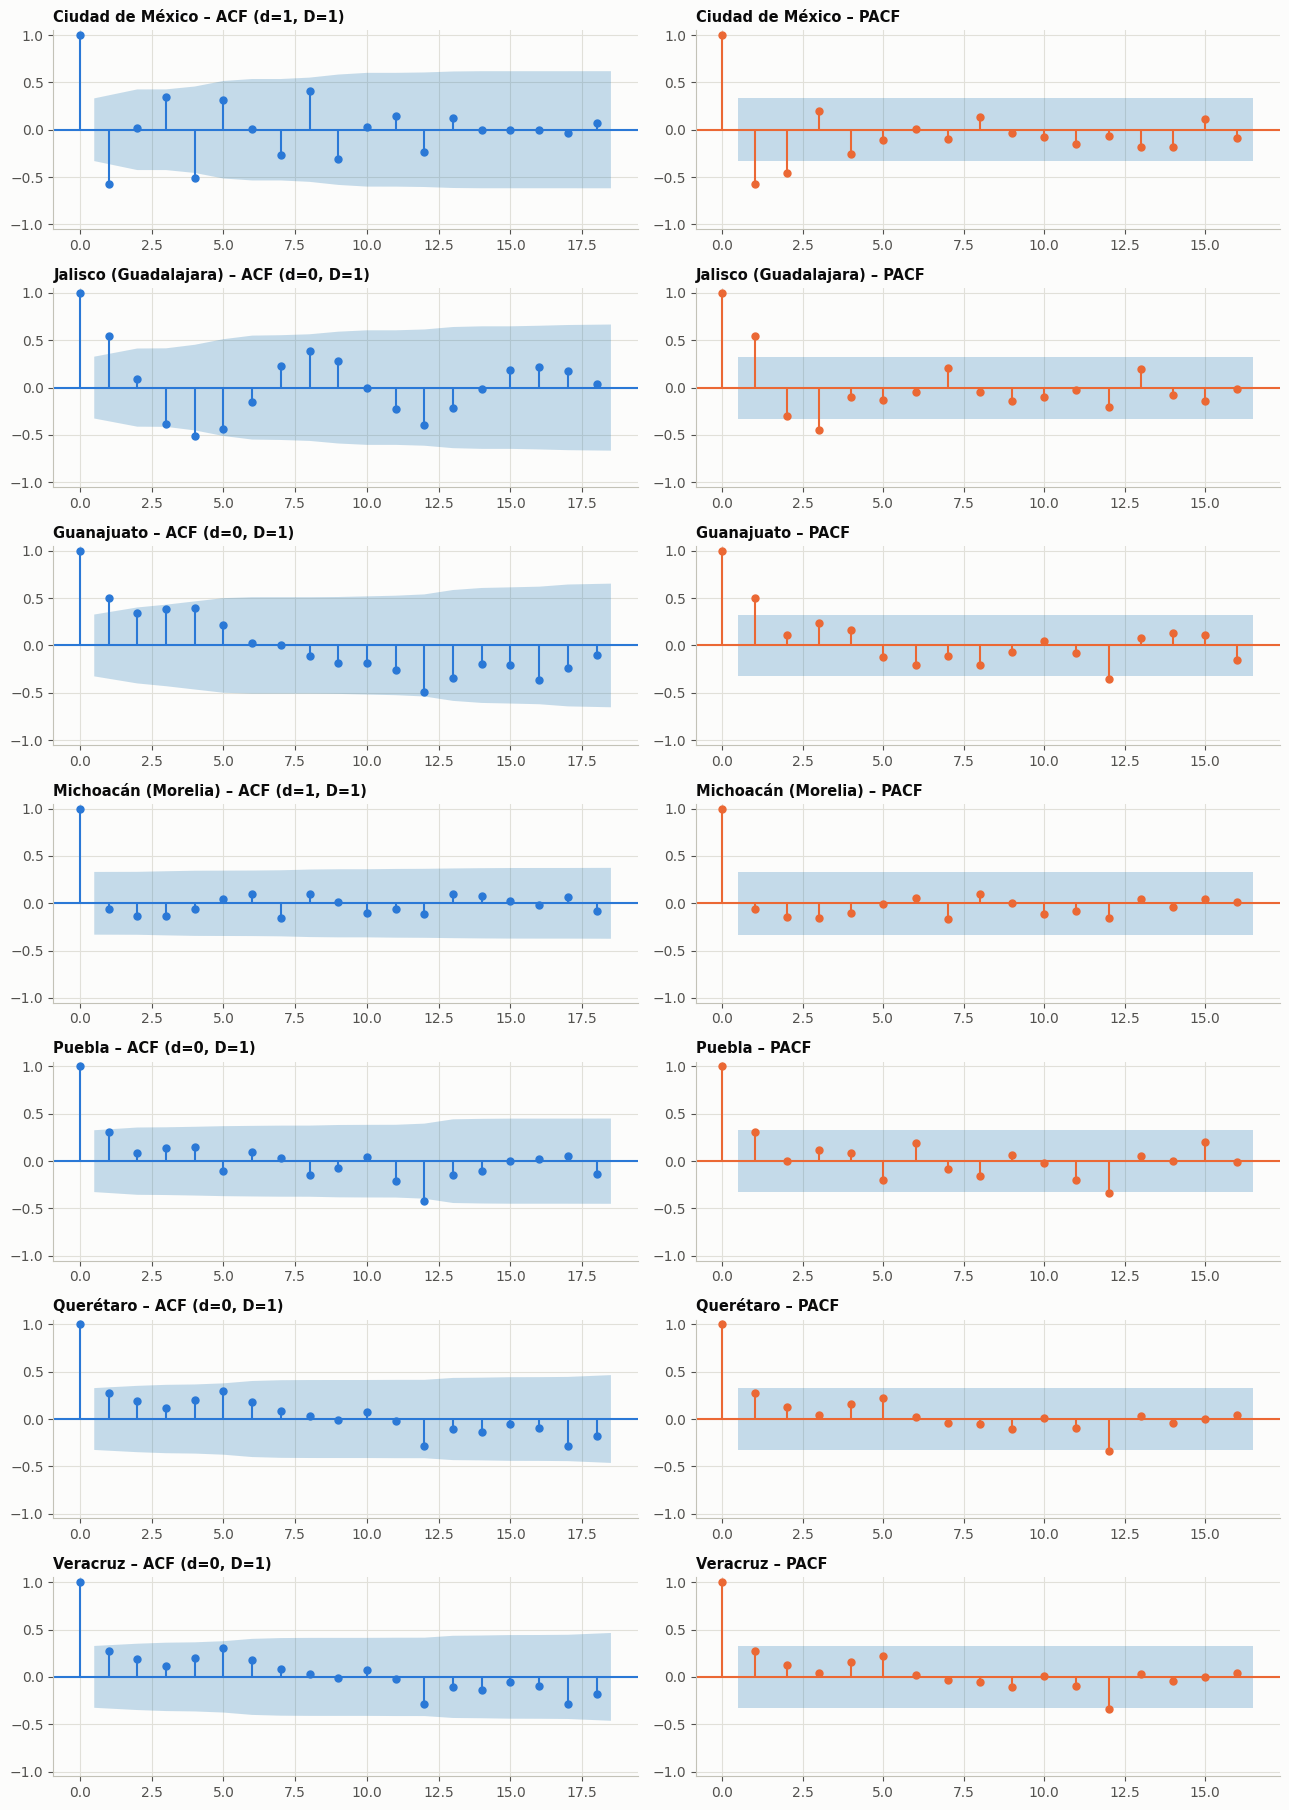

In [ ]:
def diferenciar(y, d):
    z = y.diff(12)
    return (z.diff() if d else z).dropna()

fig, axes = plt.subplots(len(ESTADOS), 2, figsize=(13, 2.6 * len(ESTADOS)))
for i, c in enumerate(ESTADOS):
    z = diferenciar(train[c], ordenes_d[c])
    plot_acf(z, lags=18, ax=axes[i, 0], color=AZUL, vlines_kwargs={'colors': AZUL}, title='')
    plot_pacf(z, lags=16, ax=axes[i, 1], color=NARANJA, vlines_kwargs={'colors': NARANJA}, method='ywm', title='')
    axes[i, 0].set_title(f'{ESTADO[c]} – ACF (d={ordenes_d[c]}, D=1)', fontsize=10.5)
    axes[i, 1].set_title(f'{ESTADO[c]} – PACF', fontsize=10.5)
    for a in axes[i]: a.set_ylim(-1.05, 1.05)
plt.tight_layout(); plt.show()

In [ ]:
def ajustar_sarima(y, d):
    mejor = None
    for p, q, P, Q in itertools.product(range(3), range(3), range(2), range(2)):
        try:
            m = SARIMAX(y, order=(p, d, q), seasonal_order=(P, 1, Q, 12)).fit(disp=False)
            if mejor is None or m.aic < mejor.aic:
                mejor, orden = m, ((p, d, q), (P, 1, Q, 12))
        except Exception:
            pass
    return mejor, orden

sar, pron_sar, orden_sar, filas = {}, {}, {}, []
for c in ESTADOS:
    m, orden = ajustar_sarima(train[c], ordenes_d[c])
    sar[c], orden_sar[c], pron_sar[c] = m, orden, m.forecast(H)
    filas.append({'Estado': ESTADO[c], 'Modelo': f'SARIMA{orden[0]}{orden[1][:3]}12', 'AIC': m.aic, **metricas(test[c], pron_sar[c])})
tab_sar = pd.DataFrame(filas).set_index('Estado')
display(tab_sar)

,Modelo,AIC,MAPE (%),MAE,RMSE
Estado,,,,,
Ciudad de México,"SARIMA(2, 1, 2)(0, 1, 1)12",639.11,14.22,"3,433.44","4,085.91"
Jalisco (Guadalajara),"SARIMA(2, 0, 2)(1, 1, 1)12",591.27,10.12,892.64,"1,055.12"
Guanajuato,"SARIMA(1, 0, 1)(1, 1, 1)12",589.31,14.89,748.86,898.02
Michoacán (Morelia),"SARIMA(0, 1, 0)(0, 1, 1)12",581.09,7.98,569.41,719.16
Puebla,"SARIMA(1, 0, 1)(0, 1, 1)12",359.37,15.07,14.55,18.68
Querétaro,"SARIMA(0, 0, 0)(0, 1, 1)12",658.85,9.53,"3,523.92","4,559.81"
Veracruz,"SARIMA(0, 0, 0)(0, 1, 1)12",658.85,9.53,"3,523.92","4,559.81"


### 8.3 Ruido blanco en los residuos
Un buen modelo deja residuos que son **ruido blanco**: sin autocorrelación, centrados en cero. Se verifica con la ACF de los residuos y con la prueba de **Ljung-Box**: si el p-valor es mayor que 0.05 no hay evidencia de autocorrelación, es decir, los residuos son ruido blanco y el modelo ya capturó la estructura de la serie. Se descartan los primeros 13 residuos, que corresponden al arranque de las diferencias.

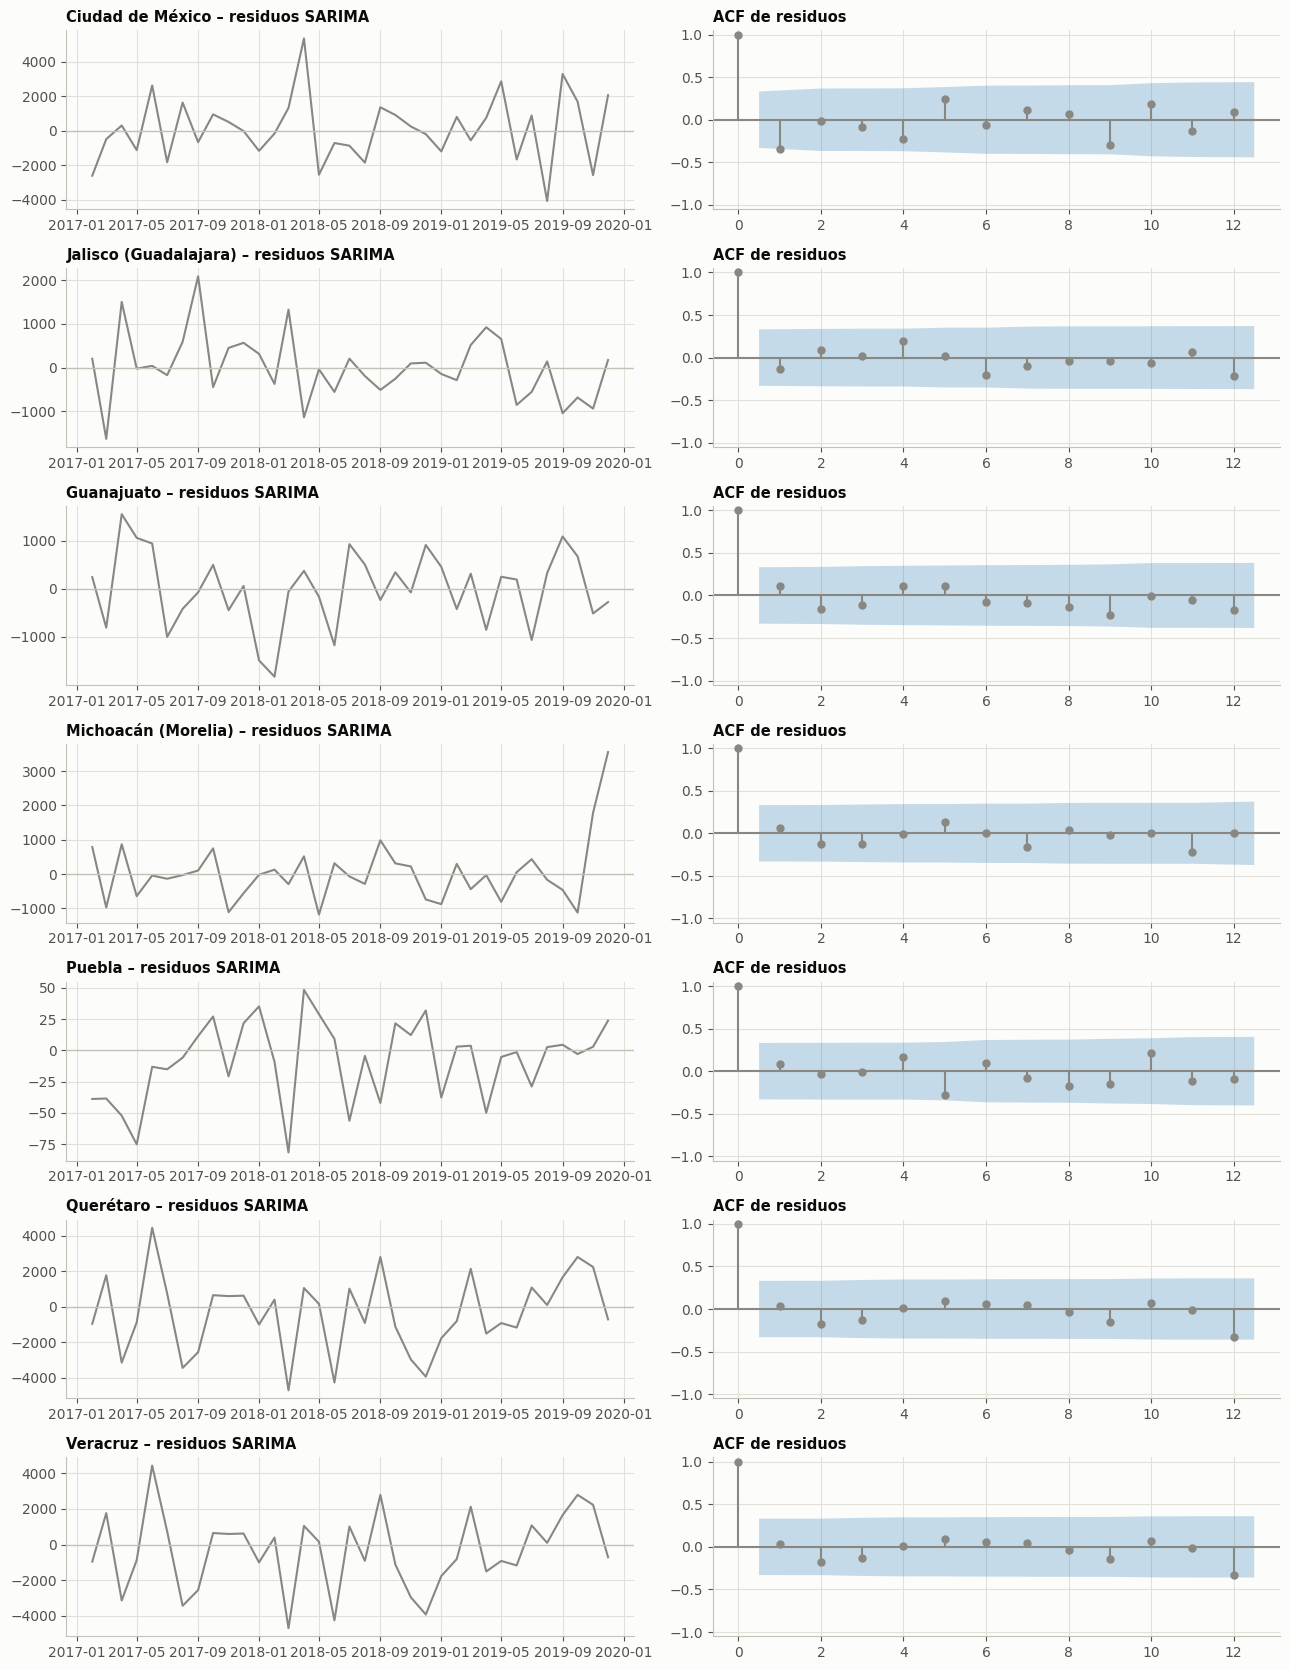

,Media residuo,p Ljung-Box (6),p Ljung-Box (12),¿Ruido blanco?
Estado,,,,
Ciudad de México,92.9,0.150,0.125,sí
Jalisco (Guadalajara),3.8,0.628,0.777,sí
Guanajuato,-2.6,0.772,0.704,sí
Michoacán (Morelia),34.6,0.899,0.904,sí
Puebla,-8.3,0.528,0.477,sí
Querétaro,-361.8,0.879,0.618,sí
Veracruz,-361.8,0.879,0.618,sí


In [ ]:
filas = []
fig, axes = plt.subplots(len(ESTADOS), 2, figsize=(13, 2.4 * len(ESTADOS)))
for i, c in enumerate(ESTADOS):
    r = sar[c].resid.iloc[13:]
    lb = acorr_ljungbox(r, lags=[6, 12], return_df=True)
    filas.append({'Estado': ESTADO[c], 'Media residuo': r.mean(), 'p Ljung-Box (6)': lb['lb_pvalue'].iloc[0],
                  'p Ljung-Box (12)': lb['lb_pvalue'].iloc[1],
                  '¿Ruido blanco?': 'sí' if lb['lb_pvalue'].min() > .05 else 'no'})
    axes[i, 0].plot(r.index, r, color=GRIS, lw=1.5); axes[i, 0].axhline(0, color='#c3c2b7', lw=1)
    axes[i, 0].set_title(f'{ESTADO[c]} – residuos SARIMA', fontsize=10.5)
    plot_acf(r, lags=12, ax=axes[i, 1], color=GRIS, vlines_kwargs={'colors': GRIS}, title='')
    axes[i, 1].set_title('ACF de residuos', fontsize=10.5); axes[i, 1].set_ylim(-1.05, 1.05)
plt.tight_layout(); plt.show()
tab_lb = pd.DataFrame(filas).set_index('Estado')
display(tab_lb.style.format({'Media residuo': '{:,.1f}', 'p Ljung-Box (6)': '{:.3f}', 'p Ljung-Box (12)': '{:.3f}'}))

## 9. Pronóstico por estado y comparativo de modelos

Para cada estado se compara el pronóstico de 2020 de ambos modelos contra las ventas reales. El modelo ganador es el de menor MAPE.

MAPE (%)                 MAE                  RMSE           Mejor modelo
Modelo                Holt-Winters SARIMA Holt-Winters   SARIMA Holt-Winters   SARIMA              
Estado                                                                                             
Ciudad de México             13.56  14.22     3,321.52 3,433.44     3,710.18 4,085.91  Holt-Winters
Guanajuato                    7.23  14.89       360.72   748.86       404.49   898.02  Holt-Winters
Jalisco (Guadalajara)        10.50  10.12       848.31   892.64     1,008.28 1,055.12        SARIMA
Michoacán (Morelia)          48.83   7.98     3,894.56   569.41     3,973.47   719.16        SARIMA
Puebla                       21.94  15.07        29.38    14.55        34.62    18.68        SARIMA
Querétaro                     8.20   9.53     3,138.53 3,523.92     4,246.04 4,559.81  Holt-Winters
Veracruz                      8.20   9.53     3,138.53 3,523.92     4,246.04 4,559.81  Holt-Winters

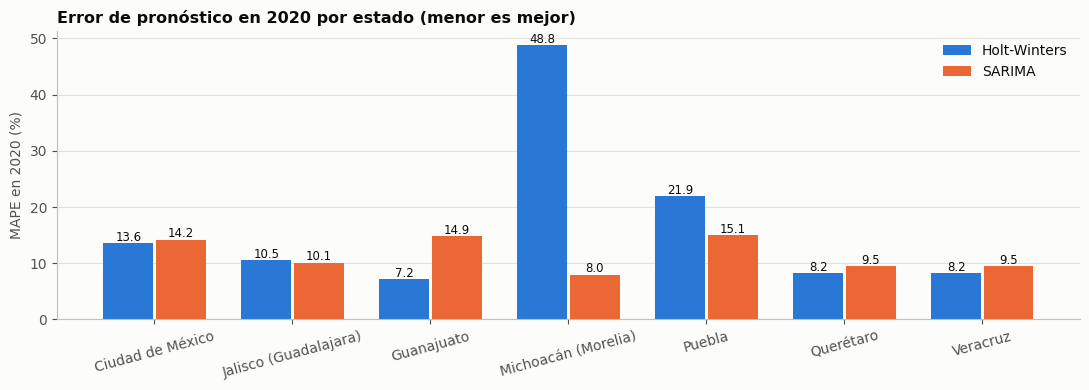

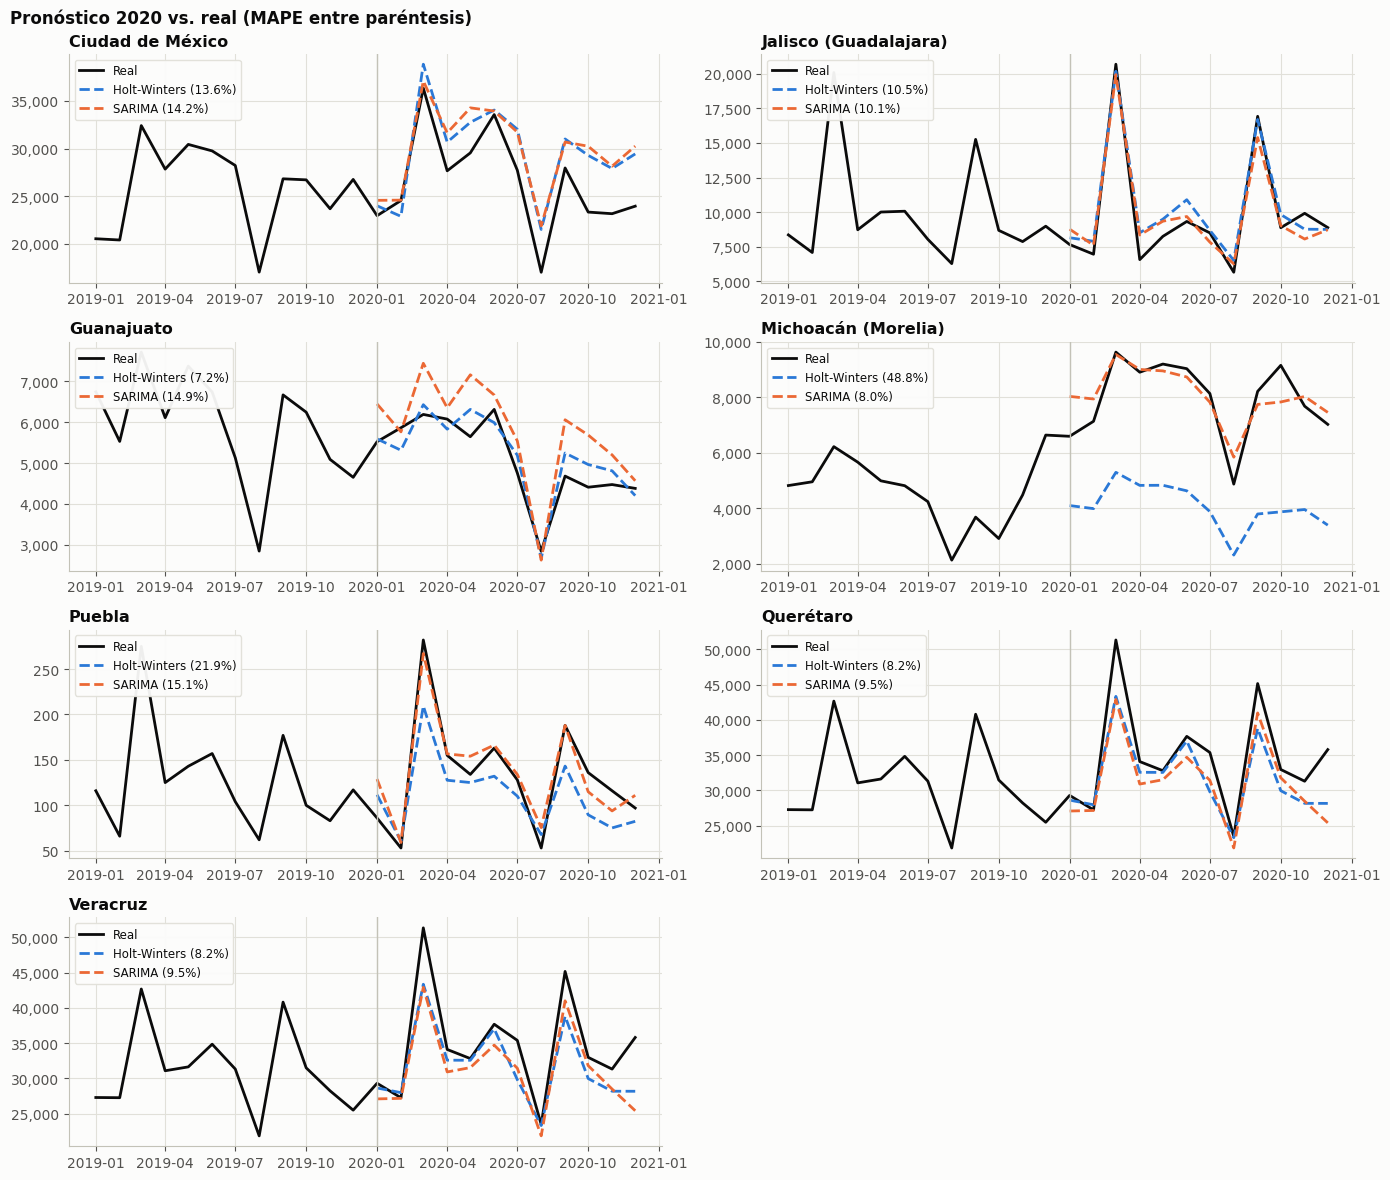

In [ ]:
comp_tab = []
for c in ESTADOS:
    for nombre, pr in [('Holt-Winters', pron_hw[c]), ('SARIMA', pron_sar[c])]:
        comp_tab.append({'Estado': ESTADO[c], 'Modelo': nombre, **metricas(test[c], pr)})
comp_tab = pd.DataFrame(comp_tab)
tabla = comp_tab.pivot(index='Estado', columns='Modelo', values=['MAPE (%)', 'MAE', 'RMSE'])
tabla['Mejor modelo'] = np.where(tabla[('MAPE (%)', 'Holt-Winters')] <= tabla[('MAPE (%)', 'SARIMA')], 'Holt-Winters', 'SARIMA')
display(tabla)
GANADOR = {c: str(np.ravel(tabla.loc[ESTADO[c], 'Mejor modelo'])[0]) for c in ESTADOS}

mp = comp_tab.pivot(index='Estado', columns='Modelo', values='MAPE (%)').loc[[ESTADO[c] for c in ESTADOS]]
fig, ax = plt.subplots(figsize=(11, 4))
x = np.arange(len(mp))
for k, mdl in enumerate(['Holt-Winters', 'SARIMA']):
    ax.bar(x + (k - .5) * .38, mp[mdl], width=.36, color=COL[mdl], label=mdl)
    for xi, v in zip(x + (k - .5) * .38, mp[mdl]):
        ax.text(xi, v + .4, f'{v:.1f}', ha='center', fontsize=8.5)
ax.set_xticks(x); ax.set_xticklabels(mp.index, rotation=15); ax.set_ylabel('MAPE en 2020 (%)')
ax.set_title('Error de pronóstico en 2020 por estado (menor es mejor)'); ax.legend(frameon=False)
ax.grid(axis='x', visible=False); plt.tight_layout(); plt.show()

fig, axes = plt.subplots(4, 2, figsize=(14, 12))
for a, c in zip(axes.ravel(), ESTADOS):
    a.plot(limpia.index[-24:], limpia[c].iloc[-24:], color=TINTA, lw=2, label='Real')
    a.plot(test.index, pron_hw[c], color=AZUL, lw=2, ls='--', label=f'Holt-Winters ({mape(test[c], pron_hw[c]):.1f}%)')
    a.plot(test.index, pron_sar[c], color=NARANJA, lw=2, ls='--', label=f'SARIMA ({mape(test[c], pron_sar[c]):.1f}%)')
    a.axvline(test.index[0], color='#c3c2b7', lw=1)
    a.set_title(ESTADO[c]); a.legend(frameon=True, facecolor='#fcfcfb', edgecolor='#e1e0d9', framealpha=.95, fontsize=8.5, loc='upper left')
    a.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:,.0f}'))
    a.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
axes.ravel()[-1].axis('off')
plt.suptitle('Pronóstico 2020 vs. real (MAPE entre paréntesis)', x=.01, ha='left', fontweight='bold')
plt.tight_layout(); plt.show()

## 10. Periodo a pronosticar con mayor confianza

Un solo año de prueba no basta para saber qué tan lejos se puede pronosticar. Se usa **origen móvil**: se entrena hasta diciembre de 2018, se pronostican 12 meses; luego se entrena hasta enero de 2019 y se vuelve a pronosticar, y así hasta diciembre de 2019 (13 orígenes). Con eso se calcula el MAPE para cada horizonte (1 mes adelante, 2 meses, …, 12 meses) con las especificaciones elegidas en las secciones 7 y 8.

Se considera confiable un horizonte con **MAPE ≤ 10%**.

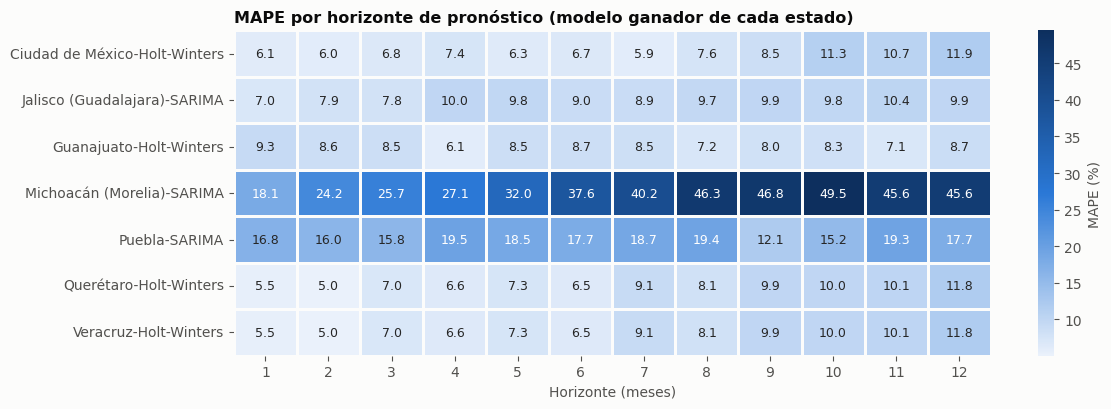

,Modelo,MAPE 1–3 meses,MAPE 4–6 meses,MAPE 7–12 meses,Meses seguidos con MAPE ≤ 10%
Estado,,,,,
Ciudad de México,Holt-Winters,6.28,6.78,9.32,9
Jalisco (Guadalajara),SARIMA,7.59,9.58,9.76,3
Guanajuato,Holt-Winters,8.80,7.75,7.97,12
Michoacán (Morelia),SARIMA,22.65,32.26,45.67,0
Puebla,SARIMA,16.23,18.60,17.10,0
Querétaro,Holt-Winters,5.83,6.80,9.85,9
Veracruz,Holt-Winters,5.83,6.80,9.85,9


In [ ]:
UMBRAL = 10
origenes = pd.date_range('2018-12-01', '2019-12-01', freq='MS')
err = {mdl: {c: np.zeros((len(origenes), 12)) for c in ESTADOS} for mdl in ['Holt-Winters', 'SARIMA']}
for c in ESTADOS:
    conf_hw = (hw[c].model.seasonal, hw[c].model.damped_trend)
    for i, o in enumerate(origenes):
        y = limpia[c].loc[:o]; real = limpia[c].loc[o + pd.DateOffset(months=1):].iloc[:12]
        f_hw = ExponentialSmoothing(y, trend='add', seasonal=conf_hw[0], seasonal_periods=12, damped_trend=conf_hw[1],
                                    initialization_method='estimated').fit().forecast(12)
        f_sa = SARIMAX(y, order=orden_sar[c][0], seasonal_order=orden_sar[c][1]).fit(disp=False).forecast(12)
        err['Holt-Winters'][c][i] = np.abs((real.values - f_hw.values) / real.values) * 100
        err['SARIMA'][c][i] = np.abs((real.values - f_sa.values) / real.values) * 100

hor = pd.DataFrame({(ESTADO[c], GANADOR[c]): err[GANADOR[c]][c].mean(axis=0) for c in ESTADOS}, index=range(1, 13)).T
hor.index.names = ['Estado', 'Modelo']; hor.columns.name = 'Horizonte (meses)'

fig, ax = plt.subplots(figsize=(12, 4.2))
sns.heatmap(hor, cmap=LinearSegmentedColormap.from_list('e', ['#eaf1fb', '#2a78d6', '#0d2f5e']), annot=True, fmt='.1f',
            annot_kws={'size': 9}, linewidths=2, linecolor='#fcfcfb', cbar_kws={'label': 'MAPE (%)'}, ax=ax)
ax.set_title('MAPE por horizonte de pronóstico (modelo ganador de cada estado)'); ax.set_ylabel(''); ax.grid(False)
plt.tight_layout(); plt.show()

filas = []
for (est, mdl), fila in hor.iterrows():
    ok = fila <= UMBRAL
    alcance = int(ok.values.argmin()) if not ok.all() else 12
    filas.append({'Estado': est, 'Modelo': mdl, 'MAPE 1–3 meses': fila.loc[1:3].mean(), 'MAPE 4–6 meses': fila.loc[4:6].mean(),
                  'MAPE 7–12 meses': fila.loc[7:12].mean(), 'Meses seguidos con MAPE ≤ 10%': alcance})
tab_hor = pd.DataFrame(filas).set_index('Estado')
display(tab_hor)

## 11. Pronóstico 2021

Con el modelo ganador de cada estado, reentrenado con los 60 meses (2016–2020), se pronostican los 12 meses de 2021 con su intervalo de confianza al 95%. Para Holt-Winters el intervalo se obtiene simulando 1,000 trayectorias futuras; para SARIMA, de la varianza del modelo. Las líneas punteadas verticales separan la historia del pronóstico; la zona sombreada indica la incertidumbre, que crece con el horizonte.

,Modelo,Ventas 2020,Pronóstico 2021,Variación (%),Mes pico 2021,Mes más bajo 2021
Estado,,,,,,
Ciudad de México,Holt-Winters,"317,823.00","287,476.63",-9.55,Mar,Ago
Jalisco (Guadalajara),SARIMA,"118,215.00","115,854.34",-2.00,Mar,Ago
Guanajuato,Holt-Winters,"61,141.00","52,547.82",-14.05,Mar,Ago
Michoacán (Morelia),SARIMA,"95,588.00","100,966.89",5.63,Mar,Ago
Puebla,SARIMA,"1,591.00","1,664.19",4.60,Mar,Feb
Querétaro,Holt-Winters,"416,485.00","491,269.63",17.96,Mar,Ago
Veracruz,Holt-Winters,"416,485.00","491,269.63",17.96,Mar,Ago


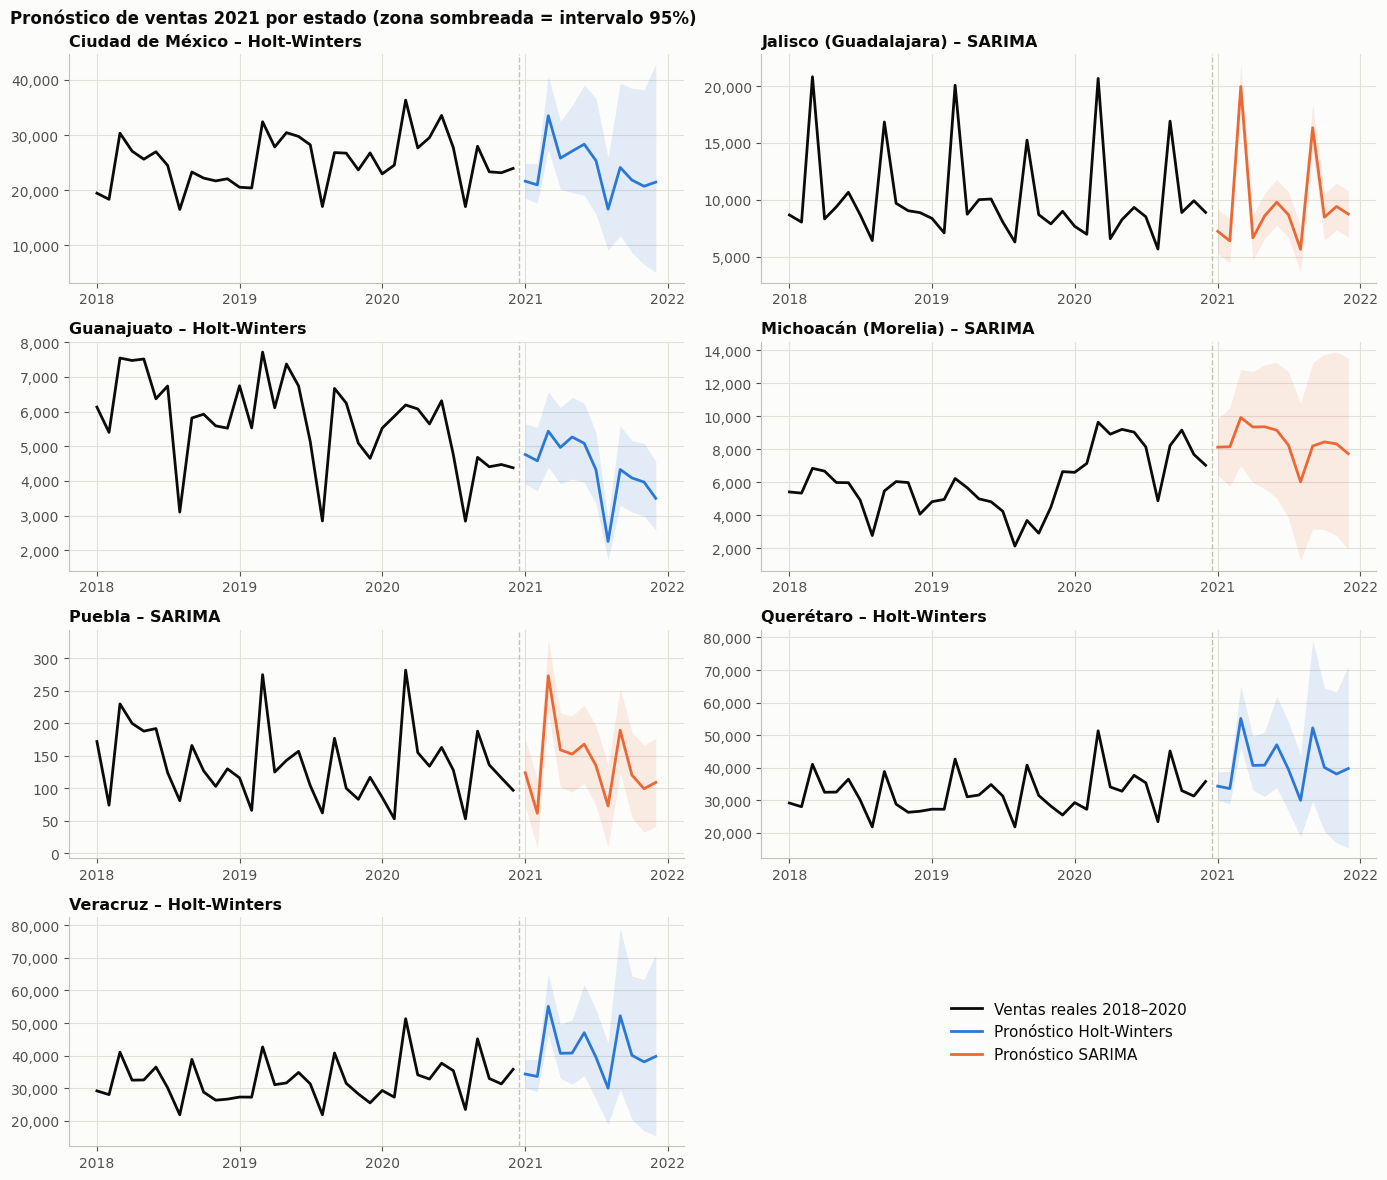

Pronóstico mensual 2021 (unidades):


,Ciudad de México,Jalisco (Guadalajara),Guanajuato,Michoacán (Morelia),Puebla,Querétaro,Veracruz
2021-01,"21,638.00","7,220.00","4,760.00","8,121.00",124.00,"34,343.00","34,343.00"
2021-02,"20,977.00","6,376.00","4,580.00","8,145.00",61.00,"33,604.00","33,604.00"
2021-03,"33,502.00","19,973.00","5,434.00","9,916.00",273.00,"55,137.00","55,137.00"
2021-04,"25,814.00","6,644.00","4,965.00","9,342.00",159.00,"40,713.00","40,713.00"
2021-05,"27,091.00","8,580.00","5,267.00","9,358.00",153.00,"40,790.00","40,790.00"
2021-06,"28,335.00","9,782.00","5,084.00","9,148.00",168.00,"47,036.00","47,036.00"
2021-07,"25,373.00","8,682.00","4,322.00","8,240.00",135.00,"39,495.00","39,495.00"
2021-08,"16,569.00","5,637.00","2,255.00","6,020.00",73.00,"29,998.00","29,998.00"
2021-09,"24,130.00","16,341.00","4,329.00","8,191.00",189.00,"52,229.00","52,229.00"
2021-10,"21,845.00","8,463.00","4,086.00","8,439.00",120.00,"40,093.00","40,093.00"


In [ ]:
pron21, filas = {}, []
fechas21 = pd.date_range(limpia.index[-1] + pd.DateOffset(months=1), periods=12, freq='MS')
for c in ESTADOS:
    if GANADOR[c] == 'Holt-Winters':
        m = hw_full[c]
        media = m.forecast(12)
        sims = m.simulate(12, repetitions=1000, error='mul' if m.model.seasonal == 'mul' else 'add', random_state=42)
        lo, hi = sims.quantile(.025, axis=1), sims.quantile(.975, axis=1)
    else:
        m = SARIMAX(limpia[c], order=orden_sar[c][0], seasonal_order=orden_sar[c][1]).fit(disp=False)
        f = m.get_forecast(12); media = f.predicted_mean; ic = f.conf_int(alpha=.05)
        lo, hi = ic.iloc[:, 0], ic.iloc[:, 1]
    pron21[c] = pd.DataFrame({'Pronóstico': media.values, 'Inferior 95%': np.maximum(lo.values, 0), 'Superior 95%': hi.values}, index=fechas21)
    filas.append({'Estado': ESTADO[c], 'Modelo': GANADOR[c], 'Ventas 2020': limpia[c].iloc[-12:].sum(),
                  'Pronóstico 2021': media.sum(), 'Variación (%)': (media.sum() / limpia[c].iloc[-12:].sum() - 1) * 100,
                  'Mes pico 2021': MESES[media.idxmax().month - 1], 'Mes más bajo 2021': MESES[media.idxmin().month - 1]})
tab21 = pd.DataFrame(filas).set_index('Estado')
display(tab21)

fig, axes = plt.subplots(4, 2, figsize=(14, 12))
for a, c in zip(axes.ravel(), ESTADOS):
    p = pron21[c]; col = COL[GANADOR[c]]
    a.plot(limpia.index[-36:], limpia[c].iloc[-36:], color=TINTA, lw=2)
    a.plot(p.index, p['Pronóstico'], color=col, lw=2)
    a.fill_between(p.index, p['Inferior 95%'], p['Superior 95%'], color=col, alpha=.12, lw=0)
    a.axvline(p.index[0] - pd.DateOffset(days=15), color='#c3c2b7', lw=1, ls='--')
    a.set_title(f'{ESTADO[c]} – {GANADOR[c]}'); a.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:,.0f}'))
    a.xaxis.set_major_locator(mdates.YearLocator()); a.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
axes.ravel()[-1].axis('off')
h = [plt.Line2D([], [], color=TINTA, lw=2), plt.Line2D([], [], color=AZUL, lw=2), plt.Line2D([], [], color=NARANJA, lw=2)]
axes.ravel()[-1].legend(h, ['Ventas reales 2018–2020', 'Pronóstico Holt-Winters', 'Pronóstico SARIMA'], loc='center', frameon=False, fontsize=11)
plt.suptitle('Pronóstico de ventas 2021 por estado (zona sombreada = intervalo 95%)', x=.01, ha='left', fontweight='bold')
plt.tight_layout(); plt.show()

detalle21 = pd.concat({ESTADO[c]: pron21[c]['Pronóstico'] for c in ESTADOS}, axis=1)
detalle21.index = detalle21.index.strftime('%Y-%m')
print('Pronóstico mensual 2021 (unidades):')
display(detalle21.round(0))
detalle21.to_csv('pronostico_2021_por_estado.csv')

## 12. Comentarios de los resultados por estado

El resumen siguiente se genera con los resultados calculados, para que sea coherente con las tablas. Después se agregan los comentarios del equipo.

In [ ]:
for c in ESTADOS:
    e = ESTADO[c]; g = GANADOR[c]
    m_hw, m_sa = mape(test[c], pron_hw[c]), mape(test[c], pron_sar[c])
    th = tab_hor.loc[e]; td = tab_desc.loc[e]; t21 = tab21.loc[e]
    outs = tab_out[tab_out['Estado'] == e]
    print(f'■ {e}')
    print(f'  Mejor modelo: {g} (MAPE 2020: Holt-Winters {m_hw:.1f}% | SARIMA {m_sa:.1f}%). '
          f'Residuos SARIMA ruido blanco: {tab_lb.loc[e, "¿Ruido blanco?"]}.')
    print(f'  Tendencia 2016→2020: {td["Cambio de tendencia 2016→2020 (%)"]:+.1f}%. Estacionalidad: pico en '
          f'{td["Mes con mayor estacionalidad"]}, valle en {td["Mes con menor estacionalidad"]}.')
    print(f'  Confianza por horizonte: MAPE {th["MAPE 1–3 meses"]:.1f}% a 1–3 meses, {th["MAPE 7–12 meses"]:.1f}% a 7–12 meses; '
          f'{int(th["Meses seguidos con MAPE ≤ 10%"])} meses seguidos con MAPE ≤ 10%.')
    print(f'  Atípicos: {len(outs)} ' + (f'({", ".join(outs["Fecha"].tolist()[:4])}{"…" if len(outs) > 4 else ""})' if len(outs) else ''))
    print(f'  Pronóstico 2021: {t21["Pronóstico 2021"]:,.0f} unidades ({t21["Variación (%)"]:+.1f}% vs 2020).\n')

■ Ciudad de México
  Mejor modelo: Holt-Winters (MAPE 2020: Holt-Winters 13.6% | SARIMA 14.2%). Residuos SARIMA ruido blanco: sí.
  Tendencia 2016→2020: +16.5%. Estacionalidad: pico en Mar, valle en Ago.
  Confianza por horizonte: MAPE 6.3% a 1–3 meses, 9.3% a 7–12 meses; 9 meses seguidos con MAPE ≤ 10%.
  Atípicos: 1 (2018-04)
  Pronóstico 2021: 287,477 unidades (-9.5% vs 2020).

■ Jalisco (Guadalajara)
  Mejor modelo: SARIMA (MAPE 2020: Holt-Winters 10.5% | SARIMA 10.1%). Residuos SARIMA ruido blanco: sí.
  Tendencia 2016→2020: -12.7%. Estacionalidad: pico en Mar, valle en Ago.
  Confianza por horizonte: MAPE 7.6% a 1–3 meses, 9.8% a 7–12 meses; 3 meses seguidos con MAPE ≤ 10%.
  Atípicos: 13 (2018-01, 2018-02, 2018-03, 2018-04…)
  Pronóstico 2021: 115,854 unidades (-2.0% vs 2020).

■ Guanajuato
  Mejor modelo: Holt-Winters (MAPE 2020: Holt-Winters 7.2% | SARIMA 14.9%). Residuos SARIMA ruido blanco: sí.
  Tendencia 2016→2020: -44.3%. Estacionalidad: pico en Mar, valle en Ago.
  Confi

### Comentarios del equipo
**Patrón común.** Todos los estados comparten la misma estacionalidad, así que es del producto y no de una región: **marzo** es el mes más alto (índice de 1.22 a 2.04) y **agosto** el más bajo (0.51 a 0.71; en Puebla febrero y agosto empatan). Jalisco, Puebla y Querétaro/Veracruz tienen además un **segundo pico en septiembre** (1.25 a 1.53). Para el negocio, el inventario debe reforzarse antes de marzo y de septiembre y reducirse para agosto.

| Estado | Mejor modelo | MAPE 2020 | Comentario |
|---|---|---|---|
| **Ciudad de México** | Holt-Winters | 13.6% (SARIMA 14.2%) | Serie estable: la tendencia bajó en 2016–2017 y repuntó desde 2018 (+16.5% entre 2016 y 2020). Ambos modelos rinden igual; en 2020 sobreestimaron el cierre del año. Es confiable a corto plazo: error de 6% a 7.5% a 1–6 meses y ≤ 10% durante 9 meses. El pronóstico 2021 baja 9.5% porque el componente cíclico cayó en el segundo semestre de 2020, y su intervalo es amplio; conviene recalcularlo cada trimestre. |
| **Jalisco (Guadalajara)** | SARIMA | 10.1% (Holt-Winters 10.5%) | Todo 2018 viene casi en cero (12 registros anómalos, de 0 a 198 unidades): es un error de registro, no una caída de demanda, y se imputó con el promedio de cada mes. Tiene la estacionalidad más marcada (marzo 2.02 y septiembre 1.53 veces el promedio). Los modelos empatan en la práctica; el error se mantiene cerca de 10% en todos los horizontes. |
| **Guanajuato** | Holt-Winters | 7.2% (SARIMA 14.9%) | Tendencia claramente descendente (−44% de 2016 a 2020). Holt-Winters sigue mejor esa caída; SARIMA sobreestima. Es el estado más predecible: MAPE ≤ 10% en los 12 horizontes. El pronóstico 2021 cae 14%; es una alerta comercial para revisar distribución o competencia en la zona. |
| **Michoacán (Morelia)** | SARIMA | 8.0% (Holt-Winters 49.5%) | La serie cambió de nivel: bajó hasta su mínimo en agosto–octubre de 2019 (octubre marcado como atípico) y desde diciembre de 2019 subió a 8,000–9,600 unidades, el nivel más alto del periodo. Holt-Winters extrapoló la caída y falló; SARIMA, con una diferencia regular, se adaptó al nuevo nivel. Aun así, la validación con origen móvil da errores de 18% a 50%: el pronóstico **no es confiable** hasta que el nuevo nivel se estabilice. Conviene reentrenar cada mes e investigar la causa del salto. |
| **Puebla** | SARIMA | 15.1% (Holt-Winters 21.9%) | Volumen muy bajo (unas 150 unidades al mes, cien veces menos que Querétaro) y la serie más irregular (componente irregular de 13% del promedio). Tendencia a la baja (−37%). Ningún horizonte baja de 10% de error (16–20%), así que el pronóstico debe usarse como rango y no como cifra exacta. Conviene verificar si las unidades del archivo son las mismas que en los demás estados. |
| **Querétaro** | Holt-Winters | 8.2% (SARIMA 9.5%) | Mayor volumen y tendencia al alza (+15%). Pronóstico confiable a 9 meses (5–9% de error). Marzo de 2020 (51,337 unidades) es un atípico positivo; coincide con el inicio de la pandemia de COVID-19 en México, cuando es posible que hubiera compras anticipadas de analgésicos. El crecimiento de 18% pronosticado para 2021 extrapola la tendencia lineal y puede ser optimista. |
| **Veracruz** | Holt-Winters | 8.2% (SARIMA 9.5%) | Sus 60 meses son **idénticos** a los de Querétaro, por lo que todos sus resultados coinciden. Lo más probable es un error en el archivo (una columna copiada); antes de usar este pronóstico hay que pedir los datos correctos de Veracruz. |

**Conclusiones generales**
- **Intervalo:** mensual, por ser el más fino disponible y conservar los picos de marzo y septiembre.
- **Periodo de mayor confianza:** los **primeros 3 meses** del pronóstico. En Ciudad de México, Jalisco, Guanajuato y Querétaro el error a 1–3 meses es de 6% a 9%; en Ciudad de México y Querétaro se mantiene ≤ 10% hasta 9 meses. Morelia y Puebla no alcanzan ese nivel en ningún horizonte.
- **Modelos:** Holt-Winters gana en 4 estados (Ciudad de México, Guanajuato, Querétaro y Veracruz) y SARIMA en 3 (Jalisco, Morelia y Puebla). La diferencia es pequeña salvo en Guanajuato (gana Holt-Winters por su tendencia descendente) y en Morelia y Puebla (gana SARIMA). Los residuos de SARIMA son ruido blanco en todos los estados, así que el modelo capturó la estructura de cada serie.
- **Calidad de datos:** antes de usar estos pronósticos para compras conviene corregir Jalisco 2018 y Veracruz en la fuente.